# Part C — Model comparison diagnostics

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step3_model_comparison/` (`evidence_per_unit_tod.csv`, `maxlike_per_unit_tod.csv`: pipeline step 3), `paper_outputs/pipeline/step2_ring_tods/``ring_tods.npz` (the points of every rerun, Haslam and the TRIS rings: pipeline step 2), `configs/model_comp_config.yaml`, `error_bars.csv` |
| **Writes** | `paper_outputs/model_comparison/diagnostic_plots/` |
| **Feeds the paper** | Section 5 tie/borderline counts (main.tex:501) |

**Pipeline:** the comparison it diagnoses is pipeline step 3: every allowed map, **TRIS excluded by design**, UltraNest evidence. The stored outputs read the 2026-10-29 `run_comparison.py` results (four points); step 3's products from the 2026-11-16 run have 11 points.

## Model comparison diagnostics

Diagnostics for the spectral-model comparison in `model_comparison/` (power law, curved power law, moment expansion
of order 2 and of order 3, per TRIS ring sample on the TOD route). Nothing here edits that module or reruns the full
comparison.

**What the comparison is decided on** is `comparison.statistic` in `configs/model_comp_config.yaml`, and this notebook
follows it:

* `max_likelihood`: each model's best fit, ln L_max = −χ²_min/2 + const.
  **No Occam penalty**, so a model is not penalised for its extra parameters. A model that contains another (the
  curved power law is the power law at C = 0) can never do worse than it. Read from
  `results/maxlike_per_unit_tod.csv`.
* `evidence`: UltraNest's ln Z, which includes the Occam penalty. Read from `results/evidence_per_unit_tod.csv`.

**Which data sets** go into every SED: the maps `sed.exclude_maps` (`configs/run_pipeline.yaml`) leaves in, plus TRIS
unless `comparison.exclude_tris`. Every rerun here builds its points with `run_comparison.select_datasets`, so it uses the same
data as the comparison.

* **Part 1** (always runs) reads the comparison's per-sample CSV for the chosen statistic and looks at the
  **per-sample** differences between models. No sums over samples: neighbouring ring samples are 3° apart under a
  ~20° beam, so they are strongly correlated and a sum would overstate the difference.
* **Parts 2–4 are evidence diagnostics** (UltraNest, Occam penalty included). With `statistic: max_likelihood` they
  are kept for reference: they show how the evidence would read the same data, and how big the Occam penalty is.
  * **Part 2** (`RUN_RERUNS`) reruns the four models for a few samples to get posteriors, best fits and maximum
    likelihoods.
  * **Part 3** (`RUN_PRIOR_SENSITIVITY`) reruns the curved power law with a narrower prior on the curvature C.
  * **Part 4** (`RUN_CONVERGENCE`) checks that UltraNest's ln Z has converged: against an exact grid integral, over
    seeds, live points and the stopping rule.
* **Part 5** (`RUN_ML_FITS`) fits every model at every ring sample (maximum likelihood, the same fitter as
  `run_comparison.max_likelihood`) and shows the fitted models at the TRIS frequencies against the TRIS rings, and the
  χ² of every fit. With `statistic: max_likelihood` it is checked against the comparison's own CSV.

Reruns use the same `model_comp_config.yaml`, priors, data sets, UltraNest settings, error table (`error_bars.csv`) and ring TODs
(`sed.tod_beam`) as `run_comparison.py`, and are cached in `paper_outputs/model_comparison/diagnostic_plots/cache/`, so a cached
sample is never rerun. Every figure is shown here and saved as a PNG in `paper_outputs/model_comparison/diagnostic_plots/`.

### Settings
All paths, sample numbers and flags. Switch a flag to `True` to run that part.

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import copy
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
MC_DIR = REPO / "scripts" / "model_comparison"
EV_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "evidence_per_unit_tod.csv"   # statistic: evidence
ML_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "maxlike_per_unit_tod.csv"     # statistic: max_likelihood
CONFIG_PATH = REPO / "configs" / "model_comp_config.yaml"
ERRORS_CSV = REPO / "configs" / "error_bars.csv"
PLOT_DIR = REPO / "paper_outputs" / "model_comparison" / "diagnostic_plots"
CACHE_DIR = PLOT_DIR / "cache"

# ---- flags ----
RUN_RERUNS = True               # Part 2: rerun the four models for RERUN_UNITS
RUN_PRIOR_SENSITIVITY = True    # Part 3: rerun the curved power law with narrower C priors
RUN_CONVERGENCE = True          # Part 4: convergence tests of the evidence (about 5 min, cached)
RUN_ML_FITS = True              # Part 5: maximum-likelihood fit of every model at every ring sample (cached)

# ---- samples (TOD-route unit = TRIS ring sample index; its RA is read from the CSV) ----
RERUN_UNITS = [0, 40, 75, 89, 100, 102]
SENS_UNITS = [0, 40, 75, 100, 102]
C_HALF_WIDTHS = [0.5, 0.2, 0.1]  # 0.5 is model_comp_config.yaml's prior; the others override it here
CONV_UNITS = [0, 89, 102]        # Part 4: a tie (0), a power-law win (89), a curved win at Cygnus (102)
CONV_SEEDS = [1, 2, 3, 4, 5]     # Part 4: repeat runs at the default settings
CONV_LIVE = [100, 1600]          # Part 4: live points tried besides model_comp_config.yaml's default (400)
CONV_STRICT_DLOGZ = 0.1          # Part 4: a stricter stopping rule than model_comp_config.yaml's 0.5
# Part 4: grid points per axis for the exact integral, by number of parameters (two per model, to show it
# has converged).  The 4-parameter order-3 model uses fewer points per axis: 81^4 would be 43 million points.
GRID_N = {2: [41, 81], 3: [41, 81], 4: [25, 41]}

# ---- what the comparison is decided on: model_comp_config.yaml comparison.statistic ----
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
STAT = (cfg.get("comparison") or {}).get("statistic", "evidence")
ML_STAT = STAT == "max_likelihood"
CSV_PATH = ML_CSV if ML_STAT else EV_CSV
ML_STARTS = int((cfg.get("comparison") or {}).get("ml_starts", 24))   # Part 5: as run_comparison.max_likelihood
SC = "lnL_max" if ML_STAT else "lnZ"          # the per-model score
DSC = "Δ" + SC                                # a difference of scores
FIGTAG = "dlnLmax" if ML_STAT else "dlogZ"    # Part 1 figure file names
TIE = 1.0                        # |Δ| < 1: indistinguishable (for lnL_max: |Δχ²| < 2)
STRONG = 2.0                     # |Δ| > 2: strong (for lnL_max: |Δχ²| > 4)
CYG_A_RA = 299.9                 # deg
N_CURVE_SAMPLES = 1000           # posterior draws used for the model bands

PL, CURVED = "power law", "curved power law"
MOMENT, MOMENT3 = "moment expansion (order 2)", "moment expansion (order 3)"
ALL4 = (PL, CURVED, MOMENT, MOMENT3)
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment (2nd order)", MOMENT3: "moment (3rd order)"}
# Okabe-Ito, colourblind-safe
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73", MOMENT3: "#CC79A7"}
UNIT_COLS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
# 5-class diverging (PuOr, colourblind-safe), grey midpoint
CLASS_COLS = ["#542788", "#998ec3", "#d9d9d9", "#f1a340", "#b35806"]
POINT_NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA 35",
               "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "CHIPASS_1400MHz.fits": "CHIPASS 1400", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420",
               "RHODES_HARTRAO_2326MHz.fits": "Rhodes 2326", "ARCADE2_315.fits": "ARCADE2 3150",
               "ARCADE2_341.fits": "ARCADE2 3410"}

plt.rcParams.update({"axes.grid": False, "figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
PLOT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure as PNG in PLOT_DIR, then show it inline."""
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(PLOT_DIR / f'{name}.png').relative_to(REPO)}")

## Part 1 — per-sample model comparison from the saved CSV

The score per model is `SC`: **ln L_max** (best fit, no Occam penalty; Δ = −Δχ²/2) with `statistic: max_likelihood`,
or **ln Z** (evidence, with its sampling error) with `statistic: evidence`. The same ±1 / ±2 bands are used for
"indistinguishable" and "strong"; for ln L_max they are Δχ² = 2 and 4.

In [2]:
P1 = CSV_PATH.exists()
# Ring samples and their RA are a property of the ring, not of the run: take them from whichever CSV exists.
_ra_src = CSV_PATH if P1 else next((p for p in (ML_CSV, EV_CSV) if p.exists()), None)
if _ra_src is None:
    raise FileNotFoundError("no comparison CSV in model_comparison/results/: run model_comparison/run_comparison.py")
_units = pd.read_csv(_ra_src).sort_values("ra_deg").reset_index(drop=True)
RA_OF = dict(zip(_units["unit"], _units["ra_deg"]))
ALL_UNITS_RING = sorted(int(u) for u in _units["unit"])

if not P1:
    print(f"PART 1 SKIPPED: {CSV_PATH.relative_to(REPO)} does not exist (comparison.statistic = {STAT}).\n"
          "Run model_comparison/run_comparison.py first.")
else:
    ev = pd.read_csv(CSV_PATH).sort_values("ra_deg").reset_index(drop=True)
    lz = {m: ev[("lnLmax " if ML_STAT else "logZ ") + m].to_numpy() for m in ALL4}
    # ln L_max has no sampling error; ln Z carries UltraNest's
    lze = {m: np.zeros(len(ev)) if ML_STAT else ev[f"logZerr {m}"].to_numpy() for m in ALL4}
    ra = ev["ra_deg"].to_numpy()

    def diff(a, b):
        return lz[a] - lz[b], np.hypot(lze[a], lze[b])

    dC, dC_err = diff(CURVED, PL)       # curved - power law
    dM, dM_err = diff(MOMENT, PL)       # moment - power law
    dM3, dM3_err = diff(MOMENT3, PL)    # moment (order 3) - power law
    dMC, dMC_err = diff(MOMENT, CURVED) # moment - curved
    dM32, dM32_err = diff(MOMENT3, MOMENT)  # moment order 3 - order 2

    print(f"comparison.statistic = {STAT}: score {SC}" + ("  (no Occam penalty)" if ML_STAT else "  (Occam penalty included)"))
    print(f"{CSV_PATH.relative_to(REPO)}: {len(ev)} ring samples, RA {ra.min():.0f}-{ra.max():.0f} deg")
    print(f"points per sample: {sorted(ev['n_points'].unique())}")
    print("inputs:", sorted(ev["inputs"].unique()))
    if ML_STAT:
        print("median χ² per sample: " + ", ".join(f"{SHORT[m]} {np.median(ev[f'chi2 {m}']):.2f}" for m in ALL4))
    else:
        print(f"ln Z error per sample (median): " + ", ".join(f"{SHORT[m]} {np.median(lze[m]):.2f}" for m in lz))
        print(f"error on a difference (median): dC {np.median(dC_err):.2f}, dM {np.median(dM_err):.2f}, dM3 {np.median(dM3_err):.2f}")

comparison.statistic = evidence: score lnZ  (Occam penalty included)
paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv: 120 ring samples, RA 0-357 deg
points per sample: [np.int64(11)]
inputs: ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
ln Z error per sample (median): power law 0.19, curved PL 0.20, moment (2nd order) 0.20, moment (3rd order) 0.20
error on a difference (median): dC 0.28, dM 0.28, dM3 0.28


#### Figure 1 — score difference along the ring
One panel per extra-parameter model (curved power law, moment expansion of order 2 and of order 3). Each point is one
TRIS ring sample: above zero the extra-parameter model scores higher than the power law, below zero the power law
does. With ln L_max (no Occam penalty) the curved power law can never be below zero, because it contains the power
law. The grey band (|Δ| < 1) means the two cannot be told apart, the faint lines at ±2 mark a strong preference, and
the dotted line is Cygnus A. Error bars only for ln Z (sampling error).

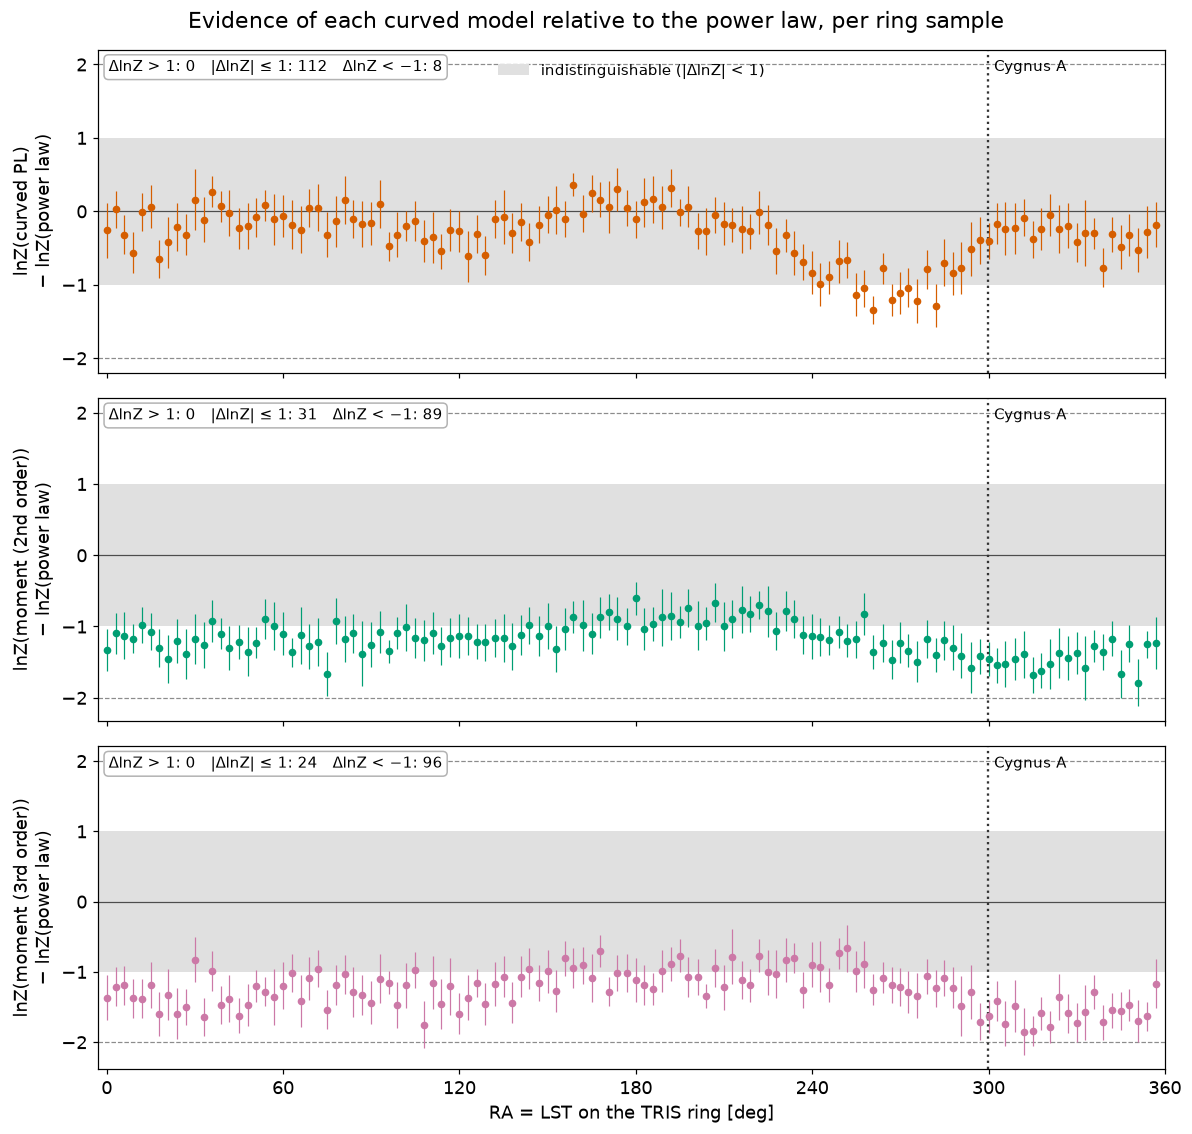

saved paper_outputs/model_comparison/diagnostic_plots/fig1_dlogZ_vs_ra.png


In [3]:
def counts3(d):
    return int((d > TIE).sum()), int((np.abs(d) <= TIE).sum()), int((d < -TIE).sum())

def yerr_of(e):
    return None if ML_STAT else e

if not P1:
    print("Figure 1 skipped: no comparison CSV.")
else:
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, d, e, m in zip(axes, (dC, dM, dM3), (dC_err, dM_err, dM3_err), (CURVED, MOMENT, MOMENT3)):
        ax.axhspan(-TIE, TIE, color="0.88", lw=0, label=f"indistinguishable (|{DSC}| < 1)")
        for y in (-STRONG, STRONG):
            ax.axhline(y, color="0.55", lw=0.8, ls="--")
        ax.axhline(0, color="0.3", lw=0.8)
        ax.errorbar(ra, d, yerr=yerr_of(e), fmt="o", ms=4, color=COL[m], ecolor=COL[m], elinewidth=0.8, capsize=0)
        ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
        ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
        up, tie, down = counts3(d)
        ax.text(0.01, 0.97, f"{DSC} > 1: {up}   |{DSC}| ≤ 1: {tie}   {DSC} < −1: {down}",
                transform=ax.transAxes, va="top", fontsize=10,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
        ax.set_ylabel(f"{SC}({SHORT[m]})\n− {SC}(power law)")
    axes[0].legend(loc="upper center", frameon=False)
    axes[-1].set_xlabel("RA = LST on the TRIS ring [deg]")
    axes[-1].set_xlim(-3, 360); axes[-1].set_xticks(np.arange(0, 361, 60))
    fig.suptitle(("Best-fit log-likelihood (no Occam penalty)" if ML_STAT else "Evidence")
                 + " of each curved model relative to the power law, per ring sample")
    fig.tight_layout()
    save(fig, f"fig1_{FIGTAG}_vs_ra")

#### Figure 2 — absolute score along the ring
The four models' score (ln L_max or ln Z) for every ring sample on one axis. The overall level follows how well the
data constrain each sample (mostly the error-bar normalisation), so read the gaps between the lines, not their height.

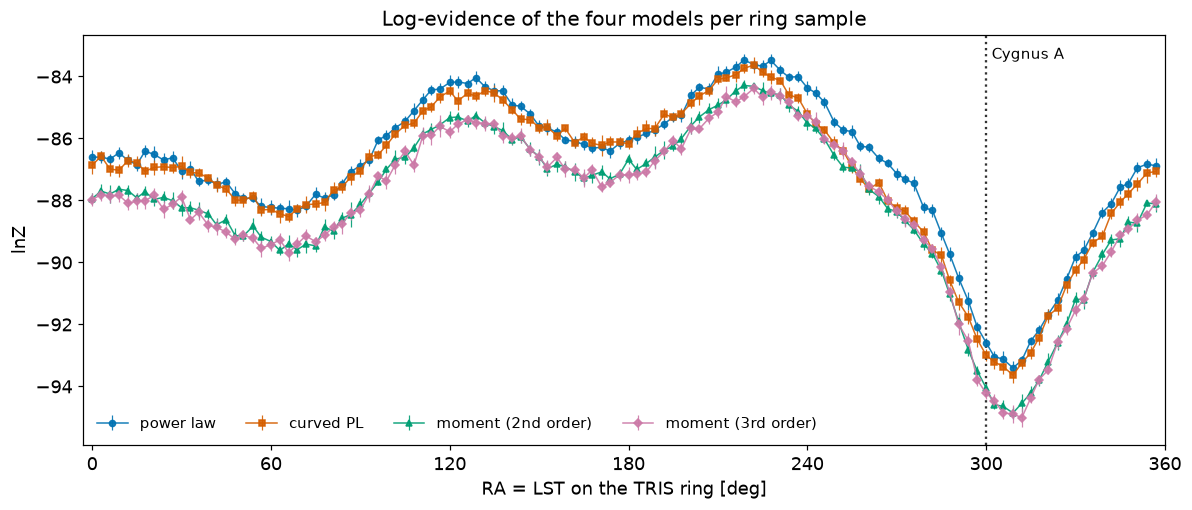

saved paper_outputs/model_comparison/diagnostic_plots/fig2_logZ_vs_ra.png


In [4]:
if not P1:
    print("Figure 2 skipped: no comparison CSV.")
else:
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for m, mk in zip(ALL4, ("o", "s", "^", "D")):
        ax.errorbar(ra, lz[m], yerr=yerr_of(lze[m]), fmt=mk + "-", ms=4, lw=1, color=COL[m], label=SHORT[m],
                    elinewidth=0.8, alpha=0.9)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
    ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel(SC)
    ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.legend(frameon=False, ncol=4, loc="lower left")
    ax.set_title(("Best-fit log-likelihood" if ML_STAT else "Log-evidence") + " of the four models per ring sample")
    fig.tight_layout()
    save(fig, "fig2_lnLmax_vs_ra" if ML_STAT else "fig2_logZ_vs_ra")

#### Figure 3 — distribution of the score differences
Histograms of Δ over the 120 ring samples, for the curved power law and the moment expansion (orders 2 and 3) against
the power law. The grey band is the indistinguishable range, the solid line is zero and the dashed line the median.

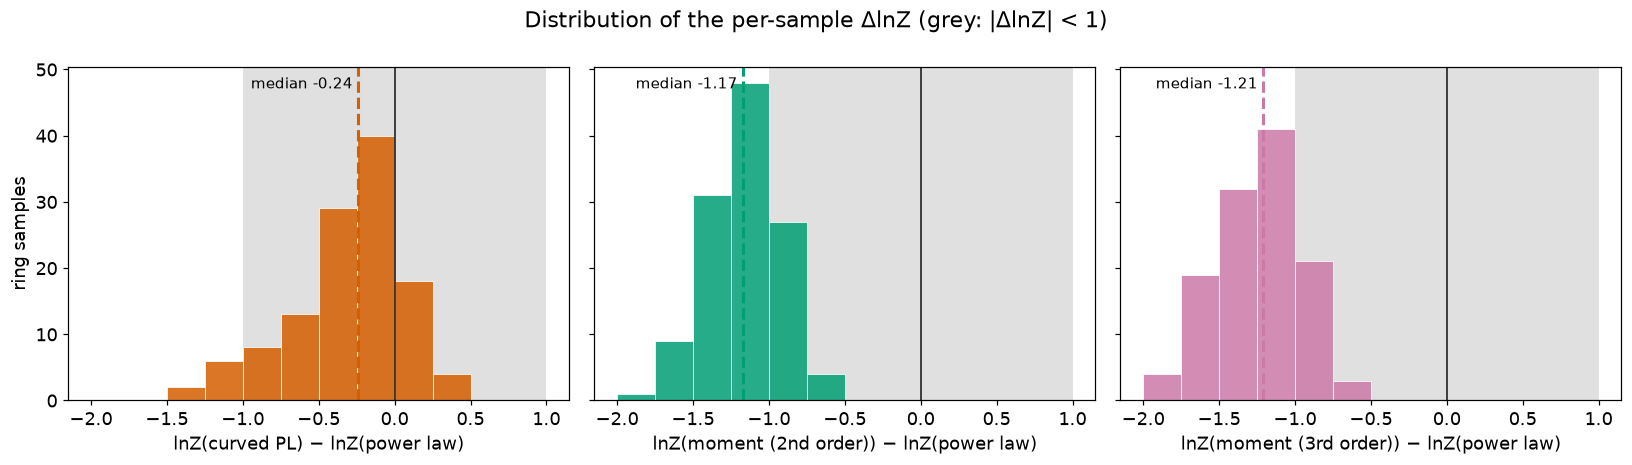

saved paper_outputs/model_comparison/diagnostic_plots/fig3_dlogZ_histograms.png


In [5]:
if not P1:
    print("Figure 3 skipped: no comparison CSV.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
    lo = np.floor(min(dC.min(), dM.min(), dM3.min())); hi = np.ceil(max(dC.max(), dM.max(), dM3.max()))
    bins = np.arange(lo, hi + 0.25, 0.25)
    for ax, d, m in zip(axes, (dC, dM, dM3), (CURVED, MOMENT, MOMENT3)):
        ax.axvspan(-TIE, TIE, color="0.88", lw=0)
        ax.hist(d, bins=bins, color=COL[m], alpha=0.85, edgecolor="white", linewidth=0.6)
        ax.axvline(0, color="0.2", lw=1.2)
        med = np.median(d)
        ax.axvline(med, color=COL[m], lw=2, ls="--")
        ax.text(med, 0.97, f" median {med:+.2f} ", transform=ax.get_xaxis_transform(), va="top",
                ha="right" if med < 0 else "left", fontsize=10)
        ax.set_xlabel(f"{SC}({SHORT[m]}) − {SC}(power law)")
    axes[0].set_ylabel("ring samples")
    fig.suptitle(f"Distribution of the per-sample {DSC} (grey: |{DSC}| < 1)")
    fig.tight_layout()
    save(fig, f"fig3_{FIGTAG}_histograms")

#### Figure 4 — how often each model is preferred
For each pair (A vs B) the bar splits the 120 ring samples by Δ = score(A) − score(B): purple means A is favoured,
orange that B is, and grey that they cannot be told apart. Read the bar's colour balance; the numbers are sample
counts.

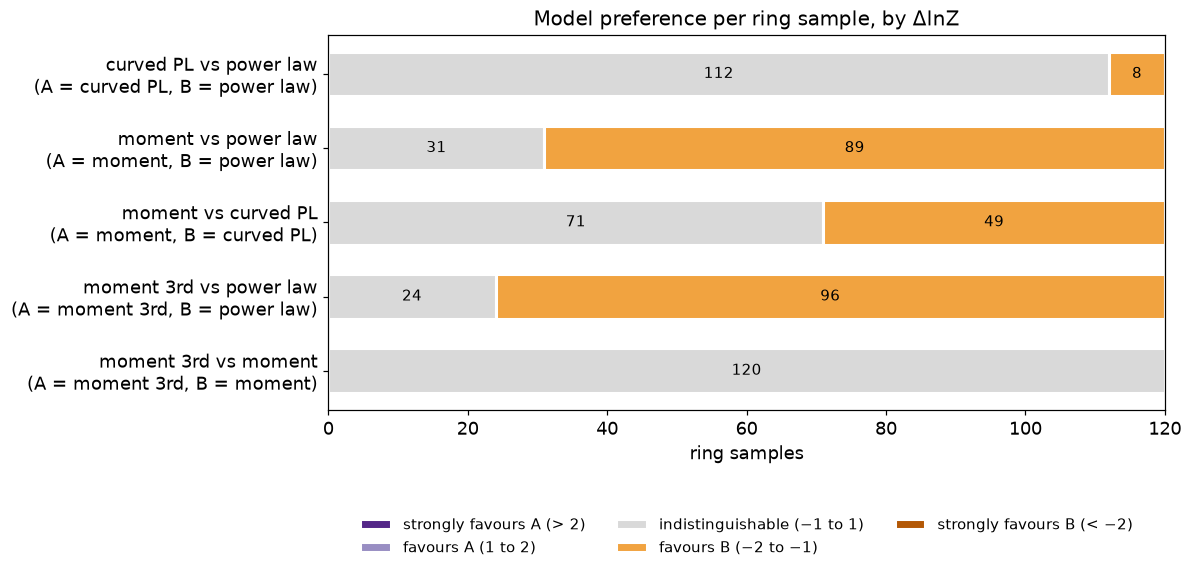

saved paper_outputs/model_comparison/diagnostic_plots/fig4_preference_counts.png
                         strongly favours A (> 2)  favours A (1 to 2)  indistinguishable (−1 to 1)  favours B (−2 to −1)  strongly favours B (< −2)
curved PL vs power law                          0                   0                          112                     8                          0
moment vs power law                             0                   0                           31                    89                          0
moment vs curved PL                             0                   0                           71                    49                          0
moment 3rd vs power law                         0                   0                           24                    96                          0
moment 3rd vs moment                            0                   0                          120                     0                          0


In [6]:
if not P1:
    print("Figure 4 skipped: no comparison CSV.")
else:
    CLASSES = [("strongly favours A (> 2)", lambda d: d > STRONG),
               ("favours A (1 to 2)", lambda d: (d > TIE) & (d <= STRONG)),
               ("indistinguishable (−1 to 1)", lambda d: np.abs(d) <= TIE),
               ("favours B (−2 to −1)", lambda d: (d < -TIE) & (d >= -STRONG)),
               ("strongly favours B (< −2)", lambda d: d < -STRONG)]
    PAIRS = [("curved PL vs power law", dC), ("moment vs power law", dM), ("moment vs curved PL", dMC),
             ("moment 3rd vs power law", dM3), ("moment 3rd vs moment", dM32)]   # "moment" = 2nd order
    table = pd.DataFrame({lab: [int(f(d).sum()) for _, d in PAIRS] for lab, f in CLASSES},
                         index=[p for p, _ in PAIRS])
    assert (table.sum(axis=1) == len(ev)).all()

    fig, ax = plt.subplots(figsize=(11, 5.6))
    y = np.arange(len(PAIRS))[::-1]
    left = np.zeros(len(PAIRS))
    for (lab, _), c in zip(CLASSES, CLASS_COLS):
        w = table[lab].to_numpy()
        ax.barh(y, w, left=left, color=c, edgecolor="white", linewidth=2, height=0.6, label=lab)
        for yi, li, wi in zip(y, left, w):
            if wi >= 4:
                ax.text(li + wi / 2, yi, str(wi), ha="center", va="center", fontsize=10,
                        color="white" if c in (CLASS_COLS[0], CLASS_COLS[4]) else "black")
        left += w
    ax.set_yticks(y); ax.set_yticklabels([f"{p}\n(A = {p.split(' vs ')[0]}, B = {p.split(' vs ')[1]})" for p, _ in PAIRS])
    ax.set_xlim(0, len(ev)); ax.set_xlabel("ring samples")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
    ax.set_title(f"Model preference per ring sample, by {DSC}")
    fig.tight_layout()
    save(fig, "fig4_preference_counts" if not ML_STAT else "fig4_preference_counts_lnLmax")
    print(table.to_string())

## Part 2 — posteriors, best fits and maximum likelihood (reruns)

**Parts 2–4 are evidence diagnostics** (UltraNest, Occam penalty included). With `comparison.statistic:
max_likelihood` they do not decide anything; they show how the evidence would read the same data. Figure 6 in
particular splits each ΔlnZ into the gain in fit (ΔlnL_max) and the Occam penalty.

**What the evidence run saves.** With `statistic: evidence`, `run_comparison.py` writes per sample only the sample
index, RA, number of points, the inputs used, and ln Z ± error for each model: no best-fit parameters, no maximum
log-likelihood and no posterior samples (`sampler.log_dir` is `null`). The next cell checks this, and then (only if
`RUN_RERUNS = True`) reruns the four models for `RERUN_UNITS` and caches each result.

In [7]:
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
EV = pd.read_csv(EV_CSV) if EV_CSV.exists() else None   # the latest evidence run, if any (may be older than the ML run)
log_dir = cfg["sampler"].get("log_dir")
sample_files = (sorted(Path(log_dir).rglob("equal_weighted_post.txt")) if log_dir and Path(log_dir).exists() else [])
if EV is not None:
    saved_cols = list(EV.columns)
    extra = [c for c in saved_cols if not c.startswith(("logZ ", "logZerr "))]
    print(f"{EV_CSV.relative_to(REPO)}: columns saved per sample:", ", ".join(extra), "+ logZ and logZerr per model")
    print("best-fit parameters saved:   ", any("best" in c or "beta" in c for c in saved_cols))
    print("max log-likelihood saved:    ", any("logl" in c.lower() or "maxl" in c.lower() for c in saved_cols))
else:
    print("no evidence CSV (comparison.statistic has not been 'evidence' yet)")
print(f"posterior samples on disk:    {bool(sample_files)}  (sampler.log_dir = {log_dir!r})")
POSTERIORS_SAVED = bool(sample_files)
if POSTERIORS_SAVED:
    print("Posterior files found: NOTE run_comparison reuses one log_dir for every sample and model, "
          "so only the last run's files survive. Not used here.")

paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv: columns saved per sample: unit, ra_deg, n_points, inputs + logZ and logZerr per model
best-fit parameters saved:    False
max log-likelihood saved:     False
posterior samples on disk:    False  (sampler.log_dir = None)


In [8]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
# Drop repo modules a long-running kernel loaded earlier, so the imports below read the current files
# (otherwise a function added to a module since the kernel started is missing until a restart).
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
import hashlib, json
# The data sets, exactly as pipeline step 3 and run_comparison choose them: the maps run_pipeline.yaml sed.exclude_maps
# leaves in, plus TRIS unless model_comp_config.yaml comparison.exclude_tris.
_RUN_CFG, TRIS_SEL, MAPS_SEL = rc.select_datasets(None, load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res",
                                                  exclude_tris=bool(cfg["comparison"]["exclude_tris"]))
DATASETS = [rc.tris_key(f) for f in TRIS_SEL] + MAPS_SEL
print("data sets:", ", ".join(POINT_NAMES.get(k, k) for k in DATASETS),
      "(run_pipeline.yaml sed.exclude_maps; TRIS {})".format("excluded" if cfg["comparison"]["exclude_tris"] else "included"))
# What the cached results were made from: the ring TODs (run_pipeline.yaml sed.tod_beam), the data sets, the error bars
# (error_bars.csv) and the target map.  Cached results made from anything else are redone.
# (The cache key holds the chosen data sets.)
TOD_KEY = json.dumps({"tod": tod_method_key(_RUN_CFG), "datasets": DATASETS,
                      "error_bars": hashlib.md5(ERRORS_CSV.read_bytes()).hexdigest(),
                      "target": _RUN_CFG.require("pipeline.target_file")}, sort_keys=True)

ALL_MODELS = build_models(cfg)
# The four models diagnosed here; model_comp_config.yaml's models.moment_orders must include both 2 and 3.
assert set(ALL4) <= set(ALL_MODELS), list(ALL_MODELS)
MODELS = {m: ALL_MODELS[m] for m in ALL4}
SCFG = cfg["sampler"]
# Moment expansion: beta fixed at model_comp_config.yaml's models.moment_beta_fixed (omega1 free), or free if null.
BETA_FIX = cfg["models"].get("moment_beta_fixed")
TAG = {PL: "base", CURVED: "base"} | {m: "base" if BETA_FIX is None else f"beta{float(BETA_FIX):g}" for m in (MOMENT, MOMENT3)}
print("moment expansion:", "beta free, omega1 = 0" if BETA_FIX is None else f"beta fixed at {float(BETA_FIX):g}, omega1 free")
assert cfg["priors"]["C"]["type"] == "uniform" and -cfg["priors"]["C"]["low"] == cfg["priors"]["C"]["high"] == 0.5

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_")

def cache_path(unit, model, tag):
    return CACHE_DIR / f"unit{unit:03d}__{slug(model)}__{tag}.npz"

# The ring TODs of every data set: pipeline step 2 (`python run_pipeline.py --step ring_tods`), read only.
from moonrunes import pipeline
RING = pipeline.load_ring_tods(_RUN_CFG)
assert str(np.load(REPO / "paper_outputs" / "pipeline" / "step2_ring_tods" / "ring_tods.npz")["tod_key"]) == tod_method_key(_RUN_CFG), \
    "step 2's ring TODs were made with other beam settings: rerun `python run_pipeline.py --step ring_tods`"
assert set(DATASETS) <= set(RING["keys"]), sorted(set(DATASETS) - set(RING["keys"]))

def unit_points(units):
    """(nu, t, s, keys) per unit: step 2's usable points of the chosen data sets, as step 3 fits them."""
    out = {}
    for u in units:
        pts = pipeline.points(RING, u, DATASETS)
        out[u] = (np.array([q[1] for q in pts]), np.array([q[2] for q in pts]),
                  np.array([q[3] for q in pts]), [q[0] for q in pts])
    return out

def run_nested(model, priors, nu, t, s):
    """The same likelihood and UltraNest call as rc.log_evidence, keeping the posterior."""
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, priors)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxlogl=res["maximum_likelihood"]["logl"], maxpoint=np.asarray(res["maximum_likelihood"]["point"]),
                names=np.array(names))

def get_results(units, model, tag, priors, allow_run):
    """{unit: result} from the cache; missing ones are run only if allow_run."""
    out, missing = {}, []
    for u in units:
        p = cache_path(u, model, tag)
        z = np.load(p, allow_pickle=False) if p.exists() else None
        if z is not None and "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY:   # from the current TODs
            out[u] = {k: z[k] for k in z.files}
        else:
            missing.append(u)
    if missing and allow_run:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        logging.getLogger("ultranest").setLevel(logging.WARNING)
        from joblib import Parallel, delayed          # independent runs: in parallel, one process per core
        pts = unit_points(missing)
        res = Parallel(n_jobs=-1)(delayed(run_nested)(model, priors, nu, t, s) for nu, t, s, keys in pts.values())
        for (u, (nu, t, s, keys)), r in zip(pts.items(), res):
            r.update(nu=nu, t=t, s=s, keys=np.array(keys), unit=u, tag=tag, tod_key=TOD_KEY)
            np.savez(cache_path(u, model, tag), **r)
            out[u] = r
            print(f"  ran unit {u:3d}, {SHORT[model]:<20} [{tag}]  lnZ = {r['logz']:.2f} ± {r['logzerr']:.2f}")
    return out

def haslam_points():
    """Haslam (the target map, NOT a fit point) through the TRIS beam, per ring sample, for plotting only: step 2's."""
    return dict(nu=RING["haslam_nu"], t=RING["haslam_T"], s=RING["haslam_S"], good=np.isfinite(RING["haslam_T"]),
                map_file=RING["target_file"])

P2 = {m: get_results(RERUN_UNITS, m, TAG[m], cfg["priors"], RUN_RERUNS) for m in MODELS}
HAS = haslam_points()
P2_UNITS = [u for u in RERUN_UNITS if all(u in P2[m] for m in MODELS)]
if not P2_UNITS:
    print("PART 2 SKIPPED: no cached reruns found and RUN_RERUNS = False. "
          "Set RUN_RERUNS = True in the settings cell to rerun units", RERUN_UNITS)
else:
    print(f"Part 2 results available for units {P2_UNITS}"
          + ("" if len(P2_UNITS) == len(RERUN_UNITS) else f" (missing: {sorted(set(RERUN_UNITS) - set(P2_UNITS))})"))
    same = []
    if EV is not None:
        _ev = EV.set_index("unit")
        same = [u for u in P2_UNITS if u in _ev.index and _ev.loc[u, "inputs"] == ";".join(str(k) for k in P2[PL][u]["keys"])]
    if same:
        print("\nrerun lnZ against the evidence CSV, where it used the same points "
              "(UltraNest is not seeded, so expect agreement within the errors):")
        for u in same:
            print(f"  unit {u:3d}: " + "   ".join(
                f"{SHORT[m]} {float(P2[m][u]['logz']):+.2f} vs {_ev.loc[u, f'logZ {m}']:+.2f}" for m in MODELS))
    else:
        print("no evidence CSV made from the same points to compare the reruns with")

data sets: LWA 35, LWA1_38.fits, LWA1_40.fits, LWA1_45.fits, Maipu 45, LWA1_50.fits, LWA1_60.fits, LWA1_70.fits, LWA1_74.fits, LWA 80, CHIPASS 1400, Stockert 1420, Rhodes 2326 (run_pipeline.yaml sed.exclude_maps; TRIS excluded)
moment expansion: beta fixed at -2.7, omega1 free
Part 2 results available for units [0, 40, 75, 89, 100, 102]

rerun lnZ against the evidence CSV, where it used the same points (UltraNest is not seeded, so expect agreement within the errors):
  unit   0: power law -86.62 vs -86.61   curved PL -86.96 vs -86.87   moment (2nd order) -87.99 vs -87.94   moment (3rd order) -88.17 vs -87.97
  unit  40: power law -84.08 vs -84.19   curved PL -84.49 vs -84.47   moment (2nd order) -85.18 vs -85.33   moment (3rd order) -85.65 vs -85.79
  unit  75: power law -83.62 vs -83.67   curved PL -84.07 vs -83.86   moment (2nd order) -84.49 vs -84.46   moment (3rd order) -84.70 vs -84.68
  unit  89: power law -87.06 vs -86.80   curved PL -88.07 vs -88.01   moment (2nd order) -88.08 

#### Figure 5 — data and fitted models for the rerun samples
Each panel is one ring sample: the SED points (the chosen data sets) (CMB-free Rayleigh–Jeans temperature) with their
error bars, and each model's posterior median with its 68% band (none for the curved power law), for all four models.
Haslam 408 MHz (open diamond) is plotted for comparison only and is not used in any fit. The small panel below shows the
residuals, data minus model in units of σ, for the power law and the curved power law.

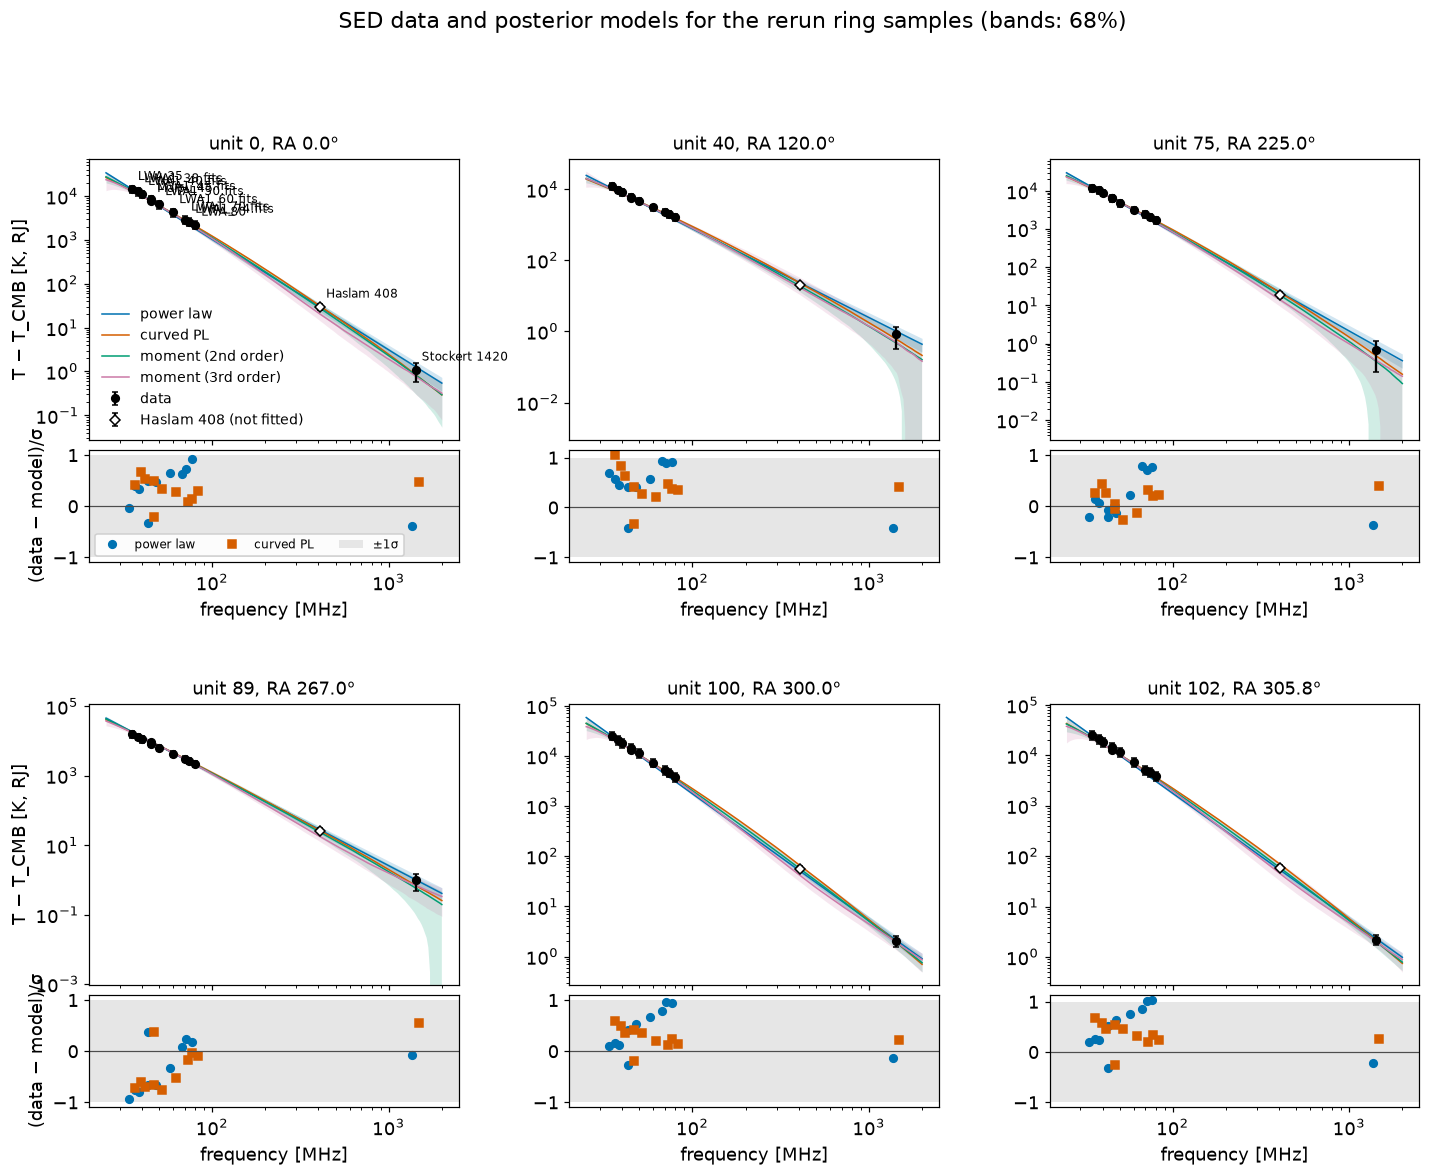

saved paper_outputs/model_comparison/diagnostic_plots/fig5_sed_fits_per_unit.png


In [9]:
def model_band(model, samples, nu):
    names, fn = MODELS[model]
    rng = np.random.default_rng(0)
    sel = samples if len(samples) <= N_CURVE_SAMPLES else samples[rng.choice(len(samples), N_CURVE_SAMPLES, replace=False)]
    curves = fn(nu, sel)
    return np.percentile(curves, [16, 50, 84], axis=0)

if not P2_UNITS:
    print("Figure 5 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    ncol = 3; nrow = int(np.ceil(len(P2_UNITS) / ncol))
    fig = plt.figure(figsize=(5.2 * ncol, 5.6 * nrow))
    outer = fig.add_gridspec(nrow, ncol, hspace=0.35, wspace=0.3)
    grid = np.geomspace(25, 2000, 200)
    for i, u in enumerate(P2_UNITS):
        g = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // ncol, i % ncol], height_ratios=[3, 1.2], hspace=0.05)
        ax = fig.add_subplot(g[0]); axr = fig.add_subplot(g[1], sharex=ax)
        r0 = P2[PL][u]; nu, t, s, keys = r0["nu"], r0["t"], r0["s"], [str(k) for k in r0["keys"]]
        for m in MODELS:
            lo_, med_, hi_ = model_band(m, P2[m][u]["samples"], grid)
            if m != CURVED:   # no band for the curved power law
                ax.fill_between(grid, lo_, hi_, color=COL[m], alpha=0.18, lw=0)
            ax.plot(grid, med_, color=COL[m], lw=1.0, label=SHORT[m])
        ax.errorbar(nu, t, yerr=s, fmt="o", color="black", ms=5, capsize=2, zorder=5, label="data")
        if HAS is not None and bool(HAS["good"][u]):   # plotted only, not in any fit
            hn, ht, hs = float(HAS["nu"]), float(HAS["t"][u]), float(HAS["s"][u])
            ax.errorbar(hn, ht, yerr=hs, fmt="D", ms=5, mfc="white", mec="black", ecolor="black",
                        capsize=2, zorder=6, label="Haslam 408 (not fitted)")
            if i == 0:
                ax.annotate("Haslam 408", (hn, ht), xytext=(4, 6), textcoords="offset points", fontsize=8)
        if i == 0:
            for n_, t_, k_ in zip(nu, t, keys):
                ax.annotate(POINT_NAMES.get(k_, k_), (n_, t_), xytext=(4, 6), textcoords="offset points", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"unit {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
        ax.tick_params(labelbottom=False)
        if i % ncol == 0:
            ax.set_ylabel("T − T_CMB [K, RJ]")
        for m, off, mk in ((PL, 0.96, "o"), (CURVED, 1.04, "s")):
            _, med_at, _ = model_band(m, P2[m][u]["samples"], nu)
            axr.plot(nu * off, (t - med_at) / s, mk, color=COL[m], ms=5, label=SHORT[m])
        axr.axhspan(-1, 1, color="0.9", lw=0, label="±1σ"); axr.axhline(0, color="0.3", lw=0.8)
        if i == 0:
            axr.legend(loc="lower left", fontsize=8, ncol=3, frameon=True, framealpha=0.9)
        axr.set_xscale("log")
        if i % ncol == 0:
            axr.set_ylabel("(data − model)/σ")
        axr.set_xlabel("frequency [MHz]")
    fig.axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    fig.suptitle("SED data and posterior models for the rerun ring samples (bands: 68%)", y=1.0)
    save(fig, "fig5_sed_fits_per_unit")

#### Figure 6 — better fit or Occam penalty?
Left: for the curved power law and the moment expansion (orders 2 and 3), how much higher their best-fit log-likelihood
is than the power law's (hatched) and how much higher their evidence is (solid); a big gain in fit
with no gain in evidence means the extra parameter is paid for by its prior. Right: each model's Occam
penalty, max lnL − lnZ, which grows with the prior volume the data rule out.

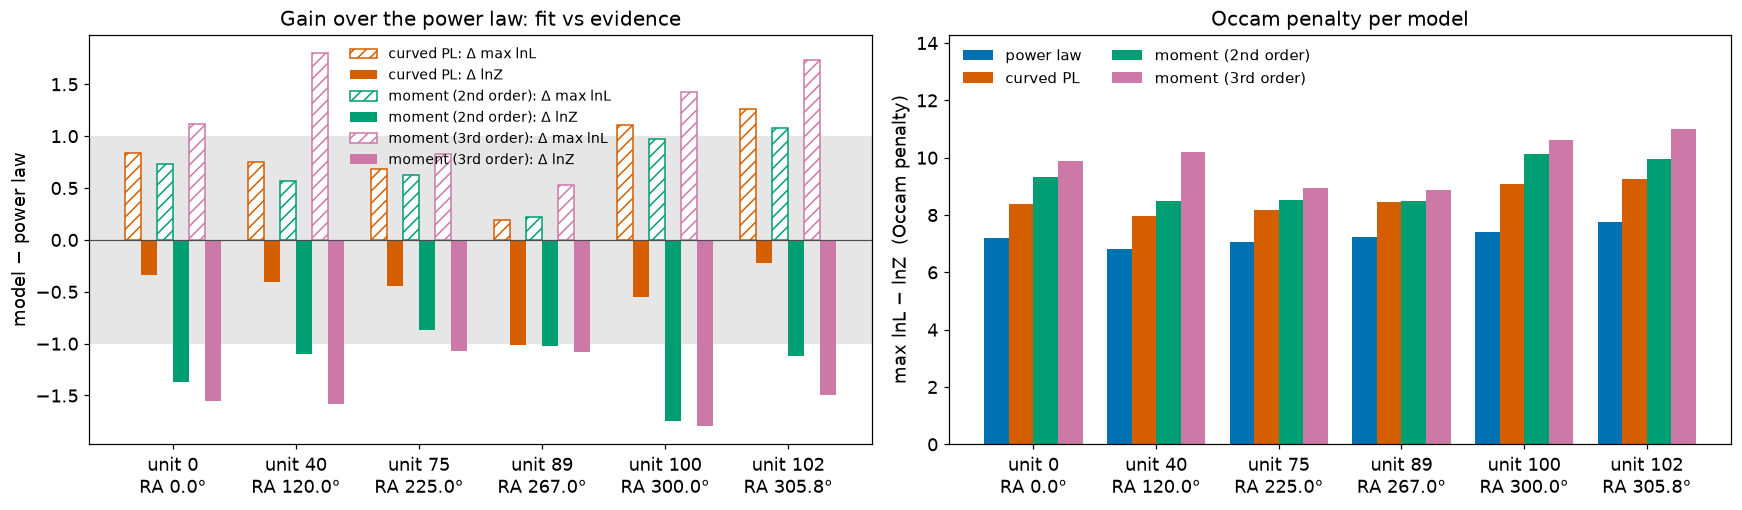

saved paper_outputs/model_comparison/diagnostic_plots/fig6_maxlogl_vs_logZ.png
     power law max lnL  curved PL max lnL  moment (2nd order) max lnL  moment (3rd order) max lnL  power law lnZ  curved PL lnZ  moment (2nd order) lnZ  moment (3rd order) lnZ
0               -79.42             -78.58                      -78.68                      -78.30         -86.62         -86.96                  -87.99                  -88.17
40              -77.27             -76.52                      -76.70                      -75.47         -84.08         -84.49                  -85.18                  -85.65
75              -76.58             -75.90                      -75.96                      -75.76         -83.62         -84.07                  -84.49                  -84.70
89              -79.81             -79.62                      -79.60                      -79.28         -87.06         -88.07                  -88.08                  -88.14
100             -84.95             -83.84

In [10]:
if not P2_UNITS:
    print("Figure 6 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    maxl = {m: np.array([float(P2[m][u]["maxlogl"]) for u in P2_UNITS]) for m in MODELS}
    lzr = {m: np.array([float(P2[m][u]["logz"]) for u in P2_UNITS]) for m in MODELS}
    x = np.arange(len(P2_UNITS)); w = 0.13
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8))
    for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
        a1.bar(x + (2 * j - 2.5) * w, maxl[m] - maxl[PL], w, color="white", edgecolor=COL[m], hatch="///",
               label=f"{SHORT[m]}: Δ max lnL")
        a1.bar(x + (2 * j - 1.5) * w, lzr[m] - lzr[PL], w, color=COL[m], label=f"{SHORT[m]}: Δ lnZ")
    a1.axhline(0, color="0.3", lw=0.8); a1.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
    a1.set_xticks(x); a1.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a1.set_ylabel("model − power law"); a1.legend(frameon=False, fontsize=9)
    a1.set_title("Gain over the power law: fit vs evidence")
    for j, m in enumerate(MODELS):
        a2.bar(x + (j - 1.5) * 0.2, maxl[m] - lzr[m], 0.2, color=COL[m], label=SHORT[m])
    a2.set_xticks(x); a2.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a2.set_ylabel("max lnL − lnZ  (Occam penalty)"); a2.set_ylim(0, 1.3 * max(float((maxl[m] - lzr[m]).max()) for m in MODELS))
    a2.legend(frameon=False, ncol=2, loc="upper left")
    a2.set_title("Occam penalty per model")
    fig.tight_layout()
    save(fig, "fig6_maxlogl_vs_logZ")
    print(pd.DataFrame({f"{SHORT[m]} max lnL": maxl[m] for m in MODELS} |
                       {f"{SHORT[m]} lnZ": lzr[m] for m in MODELS}, index=P2_UNITS).round(2).to_string())

#### Figure 7 — posterior of the curvature C
The marginal posterior of the curved power law's curvature C for each rerun ring sample, with the
prior range shaded. A posterior that fills the prior means the data do not constrain C; one well
away from zero means real curvature.

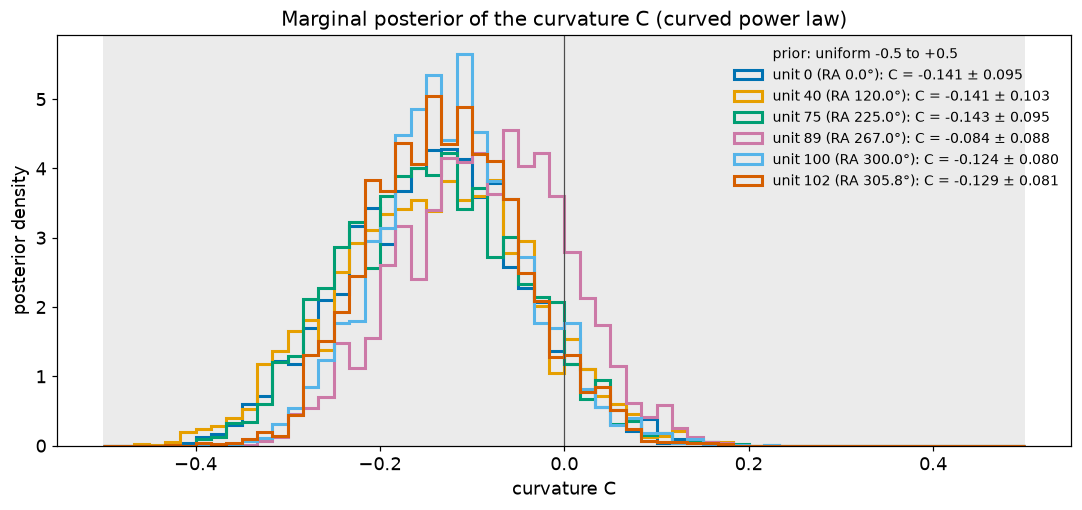

saved paper_outputs/model_comparison/diagnostic_plots/fig7_C_posterior.png


In [11]:
if not P2_UNITS:
    print("Figure 7 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    names = [str(n) for n in P2[CURVED][P2_UNITS[0]]["names"]]; ic = names.index("C")
    lo_c, hi_c = cfg["priors"]["C"]["low"], cfg["priors"]["C"]["high"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.axvspan(lo_c, hi_c, color="0.92", lw=0, label=f"prior: uniform {lo_c:+g} to {hi_c:+g}")
    bins = np.linspace(lo_c, hi_c, 61)
    for u, c in zip(P2_UNITS, UNIT_COLS):
        smp = P2[CURVED][u]["samples"][:, ic]
        ax.hist(smp, bins=bins, density=True, histtype="step", lw=2, color=c,
                label=f"unit {u} (RA {RA_OF[u]:.1f}°): C = {np.median(smp):+.3f} ± {np.std(smp):.3f}")
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlim(lo_c - 0.05, hi_c + 0.05); ax.set_xlabel("curvature C"); ax.set_ylabel("posterior density")
    ax.legend(frameon=False, fontsize=9)
    ax.set_title("Marginal posterior of the curvature C (curved power law)")
    fig.tight_layout()
    save(fig, "fig7_C_posterior")

## Part 3 — prior sensitivity of the curvature

The curved power law is rerun with the C prior narrowed from ±0.5 (config) to ±0.2 and ±0.1. The
prior is overridden here only; `model_comp_config.yaml` is not edited. The ±0.5 points and the power-law reference
are taken from Part 2's cache, and are computed only if missing.

In [12]:
P3_READY = False
if not RUN_PRIOR_SENSITIVITY and not any(cache_path(u, CURVED, f"C{w:g}").exists()
                                         for u in SENS_UNITS for w in C_HALF_WIDTHS if w != 0.5):
    print("PART 3 SKIPPED: no cached prior-sensitivity runs and RUN_PRIOR_SENSITIVITY = False. "
          "Set it to True in the settings cell to run units", SENS_UNITS)
else:
    ref = get_results(SENS_UNITS, PL, "base", cfg["priors"], RUN_PRIOR_SENSITIVITY)
    sens = {}
    for w in C_HALF_WIDTHS:
        pri = copy.deepcopy(cfg["priors"])
        pri["C"] = {"type": "uniform", "low": -w, "high": w}
        tag = "base" if w == 0.5 else f"C{w:g}"
        sens[w] = get_results(SENS_UNITS, CURVED, tag, pri, RUN_PRIOR_SENSITIVITY)
    S3_UNITS = [u for u in SENS_UNITS if u in ref and all(u in sens[w] for w in C_HALF_WIDTHS)]
    P3_READY = bool(S3_UNITS)
    if not P3_READY:
        print("Part 3: incomplete cache, nothing to plot.")

#### Figure 8 — curved-model evidence against the width of the C prior
Each line is one ring sample: lnZ(curved) − lnZ(power law) as the C prior is narrowed. If the curvature
is not needed, a narrower prior raises the curved model's evidence towards the power law's; if the data
need |C| beyond the prior, it falls.

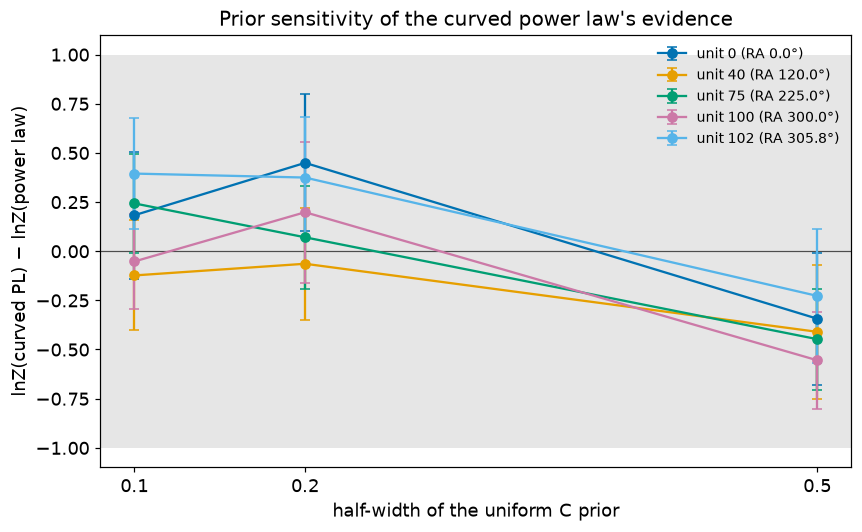

saved paper_outputs/model_comparison/diagnostic_plots/fig8_prior_sensitivity_C.png
     C ±0.5  C ±0.2  C ±0.1
0     -0.34    0.45    0.18
40    -0.41   -0.06   -0.12
75    -0.45    0.07    0.24
100   -0.55    0.20   -0.05
102   -0.23    0.37    0.39

Sign of ΔlnZ flips with the prior width for: unit 0, unit 75, unit 100, unit 102


In [13]:
if not P3_READY:
    print("Figure 8 skipped: no Part 3 results (set RUN_PRIOR_SENSITIVITY = True).")
else:
    W = np.array(C_HALF_WIDTHS)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhspan(-TIE, TIE, color="0.9", lw=0); ax.axhline(0, color="0.3", lw=0.8)
    rows, flips = {}, []
    for u, c in zip(S3_UNITS, UNIT_COLS):
        d = np.array([float(sens[w][u]["logz"]) - float(ref[u]["logz"]) for w in W])
        e = np.array([np.hypot(float(sens[w][u]["logzerr"]), float(ref[u]["logzerr"])) for w in W])
        ax.errorbar(W, d, yerr=e, fmt="o-", color=c, capsize=3, label=f"unit {u} (RA {RA_OF[u]:.1f}°)")
        rows[u] = d
        if np.any(np.sign(d) != np.sign(d[0])):
            flips.append(u)
    ax.set_xlabel("half-width of the uniform C prior"); ax.set_ylabel("lnZ(curved PL) − lnZ(power law)")
    ax.set_xticks(W); ax.legend(frameon=False, fontsize=9)
    ax.set_title("Prior sensitivity of the curved power law's evidence")
    fig.tight_layout()
    save(fig, "fig8_prior_sensitivity_C")
    print(pd.DataFrame(rows, index=[f"C ±{w:g}" for w in W]).T.round(2).to_string())
    print("\nSign of ΔlnZ flips with the prior width for:", ", ".join(f"unit {u}" for u in flips) if flips else "no unit")

## Part 4 — is the evidence converged?

ln Z comes from a sampler, so it is only an estimate. Four plain checks, each on the three ring samples
in `CONV_UNITS` and all four models, with the same data and priors as the model comparison:

1. **Exact answer.** For models with 2–4 parameters the evidence can be computed directly:
   ln Z = ln ∫ likelihood × prior, summed on a fine grid. UltraNest should land within its quoted error.
2. **Repeat runs.** The same run with 5 different random seeds. The spread should be about the quoted error.
3. **More or fewer live points, stricter stopping.** 100, 400 (the default) and 1600 live points, and
   stopping at dlogz 0.1 instead of 0.5. ln Z should not drift.
4. **Does the conclusion change?** The model comparison only uses ΔlnZ (model − power law) and the
   ±1 tie band. If every run gives the same verdict, the sampling noise does not matter.

Every run is seeded (UltraNest draws from numpy's global random generator) and cached in
`diagnostic_plots/cache/convergence/`. The tables are also saved as CSV in `diagnostic_plots/`.

In [14]:
CONV_DIR = CACHE_DIR / "convergence"
DEFAULT_LIVE, DEFAULT_DLOGZ = int(SCFG["min_num_live_points"]), float(SCFG["dlogz"])
SETTINGS = ([("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, sd) for sd in CONV_SEEDS]
            + [("live", L, DEFAULT_DLOGZ, CONV_SEEDS[0]) for L in CONV_LIVE]
            + [("dlogz", DEFAULT_LIVE, CONV_STRICT_DLOGZ, CONV_SEEDS[0])])
REF = ("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, CONV_SEEDS[0])   # the default run

def setting_label(st):
    kind, L, dz, sd = st
    if kind == "seed":
        return f"seed {sd}"
    if kind == "live":
        return f"{L} live points"
    return f"dlogz {dz:g}"

def conv_path(u, m, L, dz, sd):
    return CONV_DIR / f"unit{u:03d}__{slug(m)}__{TAG[m]}__L{L}_d{dz:g}_s{sd}.npz"

def run_setting(m, nu, t, s, L, dz, sd):
    # The same likelihood and UltraNest call as rc.log_evidence, with explicit live points, dlogz and seed.
    import ultranest
    names, fn = MODELS[m]
    transform = prior_transform(names, cfg["priors"])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(sd)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True, log_dir=None)
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=L, dlogz=dz, show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], ncall=res["ncall"], samples=res["samples"])

def grid_logz(m, nu, t, s, samples, n, width=8.0):
    # ln ∫ L x prior on an n^d grid aligned with the posterior's correlation axes (±width sigma).
    # Parameters with a log-uniform prior are integrated in ln(value), where their prior is flat.
    names, fn = MODELS[m]; d = len(names); P = cfg["priors"]
    is_log = np.array([P[k]["type"] == "loguniform" for k in names])
    lo = np.array([np.log(P[k]["low"]) if g else P[k]["low"] for k, g in zip(names, is_log)])
    hi = np.array([np.log(P[k]["high"]) if g else P[k]["high"] for k, g in zip(names, is_log)])
    x = np.array(samples, dtype=float); x[:, is_log] = np.log(x[:, is_log])
    mu, chol = x.mean(0), np.linalg.cholesky(np.cov(x.T))
    u1 = np.linspace(-width, width, n)
    X = mu + np.stack([g.ravel() for g in np.meshgrid(*[u1] * d, indexing="ij")], -1) @ chol.T
    inside = np.all((X >= lo) & (X <= hi), axis=1)          # outside the prior: zero
    theta = X[inside].copy(); theta[:, is_log] = np.exp(theta[:, is_log])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    ll = np.full(len(X), -np.inf)
    ll[inside] = np.concatenate([-0.5 * np.sum(((t - fn(nu, theta[k:k + 200000])) / s) ** 2, axis=-1) + norm
                                 for k in range(0, len(theta), 200000)])
    ll = ll.reshape([n] * d); top = ll.max(); L = np.exp(ll - top)
    for _ in range(d):
        L = np.trapezoid(L, u1, axis=-1)
    return float(np.log(L) + top - np.sum(np.log(hi - lo)) + np.log(abs(np.linalg.det(chol))))

def grid_ns(m):
    # (coarse, fine) grid points per axis for model m, from GRID_N by its number of parameters
    return GRID_N[len(MODELS[m][0])]

def exact(u, m):
    # the exact ln Z: the finer grid
    return GRID[(u, m)][grid_ns(m)[-1]]

CONV, GRID = {}, {}
def conv_cached(path):
    # A cached run counts only if it was made from the current ring TODs.
    if not path.exists():
        return None
    z = np.load(path, allow_pickle=False)
    return {k: z[k] for k in z.files} if "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY else None

have = all(conv_cached(conv_path(u, m, *st[1:])) is not None for u in CONV_UNITS for m in MODELS for st in SETTINGS)
if not (RUN_CONVERGENCE or have):
    print("PART 4 SKIPPED: set RUN_CONVERGENCE = True in the settings cell.")
else:
    CONV_DIR.mkdir(parents=True, exist_ok=True)
    pts = {u: (P2[PL][u]["nu"], P2[PL][u]["t"], P2[PL][u]["s"]) if u in P2[PL] else unit_points([u])[u][:3]
           for u in CONV_UNITS}
    # every run seeds numpy's global RNG itself (np.random.seed(sd)), so the missing runs go in parallel unchanged
    todo = [(u, m, st) for u in CONV_UNITS for m in MODELS for st in SETTINGS
            if conv_cached(conv_path(u, m, *st[1:])) is None]
    if todo:
        from joblib import Parallel, delayed
        res = Parallel(n_jobs=-1)(delayed(run_setting)(m, *pts[u], *st[1:]) for u, m, st in todo)
        for (u, m, st), r in zip(todo, res):
            np.savez(conv_path(u, m, *st[1:]), **dict(r, tod_key=TOD_KEY))
    for u in CONV_UNITS:
        nu, t, s = pts[u]
        for m in MODELS:
            for st in SETTINGS:
                CONV[(u, m, st)] = conv_cached(conv_path(u, m, *st[1:]))
            GRID[(u, m)] = {n: grid_logz(m, nu, t, s, CONV[(u, m, REF)]["samples"], n) for n in grid_ns(m)}
    print(f"{len(CONV)} UltraNest runs ({len(CONV_UNITS)} samples x {len(MODELS)} models x {len(SETTINGS)} settings), "
          f"{len(GRID)} grid integrals")

96 UltraNest runs (3 samples x 4 models x 8 settings), 12 grid integrals


#### Check 1 — UltraNest against the exact integral
`grid` is the exact ln Z at two grid resolutions (`grid points per axis`: 41 and 81 for 2–3 parameters,
25 and 41 for the 4-parameter order-3 model): if the coarse and fine columns agree, the grid has converged.
`UltraNest − grid` should be about the size of the quoted error or smaller.

In [15]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            r = CONV[(u, m, REF)]
            g = exact(u, m); nc, nf = grid_ns(m)
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "model": SHORT[m],
                         "UltraNest ln Z": float(r["logz"]), "quoted error": float(r["logzerr"]),
                         "grid points per axis": f"{nc} / {nf}",
                         "grid ln Z (coarse)": GRID[(u, m)][nc], "grid ln Z (fine)": g,
                         "UltraNest − grid": float(r["logz"]) - g})
    T1 = pd.DataFrame(rows)
    T1.to_csv(PLOT_DIR / "convergence_check1_exact.csv", index=False)
    print(T1.round(3).to_string(index=False))
    gconv = max(abs(GRID[k][grid_ns(k[1])[0]] - GRID[k][grid_ns(k[1])[-1]]) for k in GRID)
    worst = T1.loc[T1["UltraNest − grid"].abs().idxmax()]
    print(f"\nGrid resolution changes ln Z by at most {gconv:.3f}.")
    print(f"Largest |UltraNest − grid| = {abs(worst['UltraNest − grid']):.2f} "
          f"(sample {worst['sample']}, {worst['model']}; quoted error {worst['quoted error']:.2f}).")
    print(f"UltraNest within its quoted error of the exact value in "
          f"{int((T1['UltraNest − grid'].abs() <= T1['quoted error']).sum())} of {len(T1)} cases.")

 sample  RA [deg]              model  UltraNest ln Z  quoted error grid points per axis  grid ln Z (coarse)  grid ln Z (fine)  UltraNest − grid
      0      0.00          power law         -86.434         0.168              41 / 81             -86.616           -86.616             0.182
      0      0.00          curved PL         -87.023         0.222              41 / 81             -86.979           -86.980            -0.044
      0      0.00 moment (2nd order)         -87.931         0.196              41 / 81             -87.925           -87.874            -0.056
      0      0.00 moment (3rd order)         -87.700         0.241              25 / 41             -87.984           -87.966             0.266
     89    267.00          power law         -86.997         0.197              41 / 81             -86.899           -86.899            -0.098
     89    267.00          curved PL         -88.198         0.101              41 / 81             -88.001           -87.995           

#### Check 2 — the same run with five seeds
`spread` is the largest minus the smallest ln Z over the five runs, `std` their standard deviation.
If `std` is about the `typical quoted error`, the quoted error is honest.

In [16]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            z = np.array([float(CONV[(u, m, st)]["logz"]) for st in SETTINGS if st[0] == "seed"])
            e = np.array([float(CONV[(u, m, st)]["logzerr"]) for st in SETTINGS if st[0] == "seed"])
            rows.append({"sample": u, "model": SHORT[m], "mean ln Z": z.mean(), "spread": z.max() - z.min(),
                         "std": z.std(ddof=1), "typical quoted error": float(np.median(e)),
                         "mean − exact": z.mean() - exact(u, m)})
    T2 = pd.DataFrame(rows)
    T2.to_csv(PLOT_DIR / "convergence_check2_seeds.csv", index=False)
    print(T2.round(3).to_string(index=False))

 sample              model  mean ln Z  spread   std  typical quoted error  mean − exact
      0          power law    -86.568   0.424 0.178                 0.168         0.047
      0          curved PL    -86.999   0.175 0.065                 0.222        -0.019
      0 moment (2nd order)    -87.961   0.255 0.109                 0.196        -0.087
      0 moment (3rd order)    -87.950   0.405 0.175                 0.241         0.016
     89          power law    -86.993   0.359 0.157                 0.197        -0.094
     89          curved PL    -88.141   0.196 0.085                 0.211        -0.146
     89 moment (2nd order)    -88.132   0.223 0.087                 0.206         0.041
     89 moment (3rd order)    -88.072   0.353 0.152                 0.190        -0.091
    102          power law    -93.302   0.411 0.168                 0.185        -0.063
    102          curved PL    -93.429   0.395 0.183                 0.166         0.075
    102 moment (2nd order)    -9

#### Check 3 — live points and stopping rule
ln Z for 100, 400 (default) and 1600 live points, and for the stricter stop, next to the exact value.
More live points should move ln Z towards the exact value, not away from it.

In [17]:
if CONV:
    cols = [st for st in SETTINGS if st[0] != "seed" or st == REF]
    cols = sorted(cols, key=lambda st: (st[0] == "dlogz", st[1]))
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            row = {"sample": u, "model": SHORT[m]}
            for st in cols:
                row[f"{setting_label(st) if st != REF else f'{DEFAULT_LIVE} live points (default)'}"] = float(CONV[(u, m, st)]["logz"])
            row["exact (grid)"] = exact(u, m)
            rows.append(row)
    T3 = pd.DataFrame(rows)
    T3.to_csv(PLOT_DIR / "convergence_check3_settings.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T3.round(3).to_string(index=False))
    calls = {setting_label(st): int(np.median([int(CONV[(u, m, st)]["ncall"]) for u in CONV_UNITS for m in MODELS]))
             for st in cols}
    print("\nlikelihood calls per run (median):", ", ".join(f"{k}: {v}" for k, v in calls.items()))

 sample              model  100 live points  400 live points (default)  1600 live points  dlogz 0.1  exact (grid)
      0          power law          -86.682                    -86.434           -86.532    -86.500       -86.616
      0          curved PL          -86.741                    -87.023           -86.961    -86.889       -86.980
      0 moment (2nd order)          -87.631                    -87.931           -87.922    -87.790       -87.874
      0 moment (3rd order)          -87.766                    -87.700           -88.019    -87.843       -87.966
     89          power law          -86.788                    -86.997           -86.962    -87.028       -86.899
     89          curved PL          -88.481                    -88.198           -87.988    -88.190       -87.995
     89 moment (2nd order)          -88.128                    -88.261           -88.075    -88.154       -88.174
     89 moment (3rd order)          -88.087                    -87.936           -87.952

#### Check 4 — does the verdict change?
For curved − power law and moment (orders 2 and 3) − power law, ΔlnZ from every run (each run paired with the power-law run
at the same settings), and from the exact integral. The verdict uses the comparison's own rule:
> +1 favours the model, < −1 favours the power law, otherwise a tie.

In [18]:
def verdict(d):
    return "favours model" if d > TIE else ("favours power law" if d < -TIE else "tie")

if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in (CURVED, MOMENT, MOMENT3):
            d = np.array([float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"]) for st in SETTINGS])
            dg = exact(u, m) - exact(u, PL)
            v = pd.Series([verdict(x) for x in d]).value_counts()
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "comparison": f"{SHORT[m]} − power law",
                         "exact ΔlnZ": dg, "exact verdict": verdict(dg),
                         "lowest ΔlnZ": d.min(), "highest ΔlnZ": d.max(),
                         "runs agreeing with exact": f"{int((v.get(verdict(dg), 0)))} of {len(d)}"})
    T4 = pd.DataFrame(rows)
    T4.to_csv(PLOT_DIR / "convergence_check4_verdicts.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T4.round(2).to_string(index=False))

 sample  RA [deg]                     comparison  exact ΔlnZ     exact verdict  lowest ΔlnZ  highest ΔlnZ runs agreeing with exact
      0      0.00          curved PL − power law       -0.36               tie        -0.59         -0.06                   8 of 8
      0      0.00 moment (2nd order) − power law       -1.26 favours power law        -1.59         -0.95                   7 of 8
      0      0.00 moment (3rd order) − power law       -1.35 favours power law        -1.50         -1.08                   8 of 8
     89    267.00          curved PL − power law       -1.10 favours power law        -1.69         -1.02                   8 of 8
     89    267.00 moment (2nd order) − power law       -1.27 favours power law        -1.34         -0.91                   6 of 8
     89    267.00 moment (3rd order) − power law       -1.08 favours power law        -1.30         -0.90                   4 of 8
    102    305.75          curved PL − power law       -0.27               tie     

#### Figure 9 — ΔlnZ from every run, against the exact value
Each panel is one ring sample. Dots are the individual runs (5 seeds, other live points, stricter stop),
the bar is the exact value from the grid integral, and the grey band is the ±1 tie range.

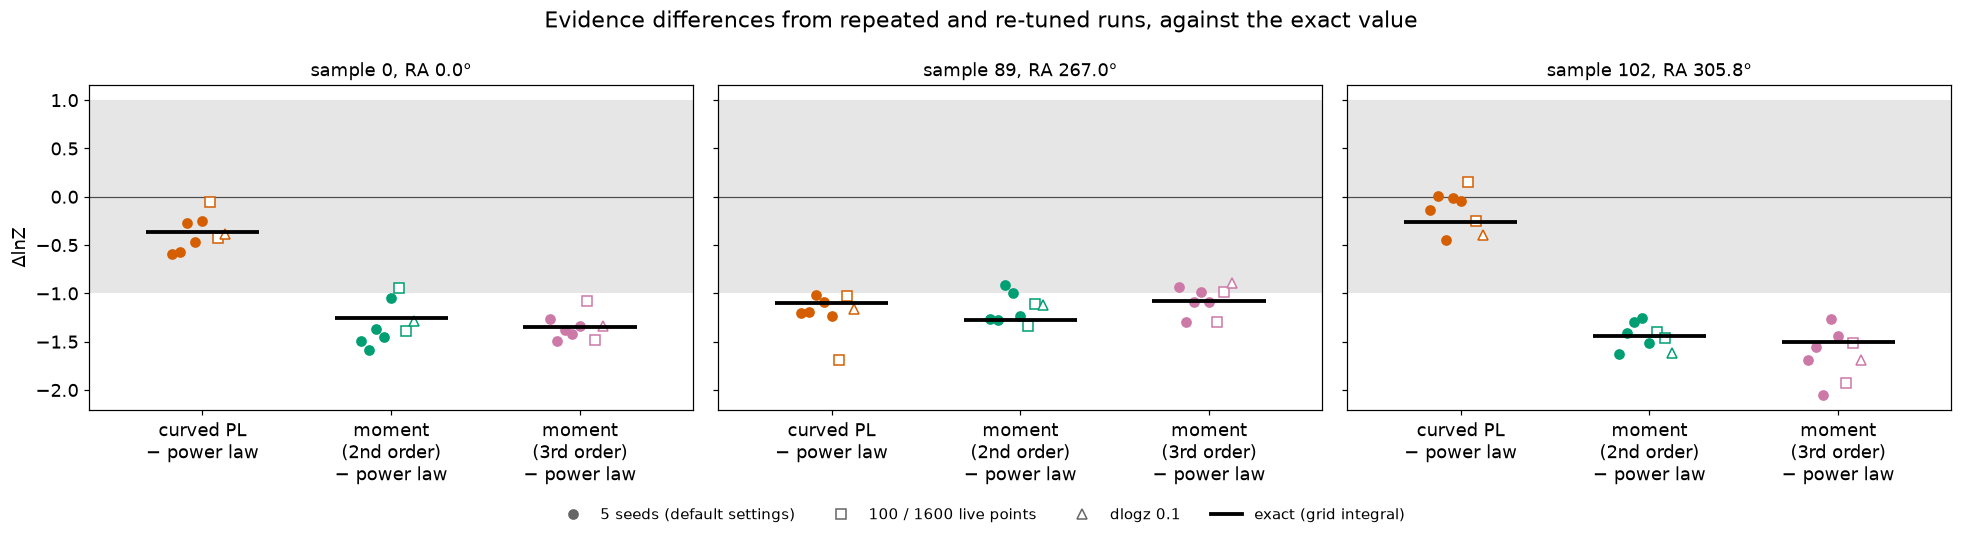

saved paper_outputs/model_comparison/diagnostic_plots/fig9_convergence_dlogZ.png


In [19]:
if CONV:
    fig, axes = plt.subplots(1, len(CONV_UNITS), figsize=(6 * len(CONV_UNITS), 4.6), sharey=True)
    marks = {"seed": "o", "live": "s", "dlogz": "^"}
    for ax, u in zip(np.atleast_1d(axes), CONV_UNITS):
        ax.axhspan(-TIE, TIE, color="0.9", lw=0)
        ax.axhline(0, color="0.3", lw=0.8)
        for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
            for k, st in enumerate(SETTINGS):
                d = float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"])
                ax.plot(j + (k - len(SETTINGS) / 2) * 0.04, d, marks[st[0]], color=COL[m], ms=6, mfc="white" if st[0] != "seed" else COL[m])
            dg = exact(u, m) - exact(u, PL)
            ax.hlines(dg, j - 0.3, j + 0.3, color="black", lw=2.5)
        ax.set_xticks([0, 1, 2]); ax.set_xticklabels([SHORT[m].replace(" (", "\n(") + "\n− power law" for m in (CURVED, MOMENT, MOMENT3)])
        ax.set_xlim(-0.6, 2.6)
        ax.set_title(f"sample {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
    np.atleast_1d(axes)[0].set_ylabel("ΔlnZ")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", ls="", color="0.4", label="5 seeds (default settings)"),
               Line2D([], [], marker="s", ls="", color="0.4", mfc="white", label="100 / 1600 live points"),
               Line2D([], [], marker="^", ls="", color="0.4", mfc="white", label=f"dlogz {CONV_STRICT_DLOGZ:g}"),
               Line2D([], [], color="black", lw=2.5, label="exact (grid integral)")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("Evidence differences from repeated and re-tuned runs, against the exact value")
    fig.tight_layout()
    save(fig, "fig9_convergence_dlogZ")

#### Part 4 in plain numbers

*Evidence diagnostics (Occam penalty included); see the note at the top of Part 2.*

Run on 2026-10-29 on the current data (beam-matched TODs; 4 points per sample: LWA1 35, Maipu 45, LWA1 80 and
Stockert 1420, no TRIS); samples 0 (RA 0°), 89 (RA 267°) and 102 (RA 305.8°); all four models; 96 UltraNest runs and
12 grid integrals; tables in `diagnostic_plots/convergence_check*.csv`.

* **The exact integral is reliable to about 0.1.** Refining the grid (41 → 81 points per axis; 25 → 41 for the
  4-parameter order-3 model) changes ln Z by at most 0.10 (the moment expansions; the power law and curved power law
  by less than 0.003). With 4 points the posteriors are broader, so the grid is coarser relative to them than before.
* **UltraNest is close to exact.** At the default settings it is off by 0.01 to 0.33 in ln Z (worst: sample 102,
  curved PL, −0.33 against a quoted error of 0.17). It is within its quoted error in 11 of 12 cases.
* **The quoted error is honest.** Over 5 seeds the scatter (std) is 0.01–0.22, against a typical quoted error of
  0.15–0.23. The mean of the 5 runs is within 0.13 of the exact value in every case.
* **Settings do not bias it.** 1600 live points and the stricter stop (dlogz 0.1) land within 0.16 of the exact
  value; 400 live points (the default) within 0.33; 100 live points is noisier (up to 0.50 off, sample 102 curved PL).
  1600 live points cost about 3.1× the likelihood calls of the default, the stricter stop about 2.6×.
* **Most verdicts sit near the ±1 line, so they are borderline.** The exact ΔlnZ against the power law is −0.57 /
  −1.10 / −1.21 at sample 0 (curved PL / moment order 2 / order 3), −0.86 / −0.91 / −0.88 at sample 89 and −0.80 /
  −1.53 / −1.70 at sample 102. Only 4 of the 9 comparisons give the exact verdict in all 8 runs; in the others 1–2 runs
  cross the ±1 line. Every run in every comparison is below zero: the power law is never worse.
* **No Cygnus curvature without TRIS.** At sample 102 the curved power law no longer wins (exact −0.80, all runs
  −1.14 to −0.11). The +3.9 of the 6-point run came from the TRIS points.

## Part 5 — the fitted models at the TRIS frequencies, and the χ² of every fit

Every model is fitted at **every** ring sample: the same points as the comparison (`run_comparison.tod_units` with the
data sets of pipeline step 3, the `error_bars.csv` errors, and TRIS with its **published** uncertainties,
`sed_prototype.ring_sigma` = statistical ⊕ published zero level), the same Gaussian likelihood and the same prior
ranges (`model_comp_config.yaml`). The fit is the **maximum likelihood inside the prior ranges** (the minimum χ²), found with
L-BFGS-B in the sampler's unit cube from `ML_STARTS` starting points (`comparison.ml_starts`, seeded): the same fitter
as `run_comparison.max_likelihood`. With `statistic: max_likelihood` these are the comparison's own best fits, and the
χ² is checked against `results/maxlike_per_unit_tod.csv`. For the Part 2 samples it is also checked against UltraNest's
maximum likelihood. Results are cached in `diagnostic_plots/cache/ml_fits_all_samples.npz` under the data key.

In [20]:
ML_CACHE = CACHE_DIR / "ml_fits_all_samples.npz"
ALL_UNITS = ALL_UNITS_RING
ML_KEY = json.dumps({"data": TOD_KEY, "priors": cfg["priors"], "models": list(MODELS),
                     "beta_fixed": cfg["models"].get("moment_beta_fixed"), "starts": ML_STARTS}, sort_keys=True)

def ml_fit(m, nu, t, s, starts):
    # Minimum chi^2 inside the prior box, searched in the unit cube of prior_transform, from the given starts.
    names, fn = MODELS[m]
    tr = prior_transform(names, cfg["priors"])
    chi2 = lambda u: float(np.sum(((t - fn(nu, tr(np.atleast_2d(u)))[0]) / s) ** 2))
    best = None
    for u0 in starts:
        r = minimize(chi2, u0, method="L-BFGS-B", bounds=[(0.0, 1.0)] * len(names))
        if best is None or r.fun < best.fun:
            best = r
    return tr(np.atleast_2d(best.x))[0]

from scipy.optimize import minimize
PTS5, FIT5 = {}, {m: {} for m in MODELS}
z = np.load(ML_CACHE, allow_pickle=False) if ML_CACHE.exists() else None
if z is not None and str(z["key"]) == ML_KEY:
    for u in ALL_UNITS:
        PTS5[u] = (z[f"u{u}__nu"], z[f"u{u}__t"], z[f"u{u}__s"], [str(k) for k in z[f"u{u}__keys"]])
        for m in MODELS:
            FIT5[m][u] = z[f"u{u}__{slug(m)}"]
    print(f"Part 5: maximum-likelihood fits loaded from {ML_CACHE.relative_to(REPO)}")
elif not RUN_ML_FITS:
    print("PART 5 SKIPPED: no matching cache and RUN_ML_FITS = False.")
else:
    PTS5 = unit_points(ALL_UNITS)
    # starting points drawn in the serial order (sample by sample, model by model), then the fits in parallel:
    # the same fits as one by one
    from joblib import Parallel, delayed
    rng = np.random.default_rng(0)
    jobs = []
    for u in ALL_UNITS:
        nu, t, s, keys = PTS5[u]
        for m in MODELS:
            n = len(MODELS[m][0])
            jobs.append((u, m, np.vstack([np.full(n, 0.5), rng.uniform(0.02, 0.98, (ML_STARTS - 1, n))])))
    res = Parallel(n_jobs=-1)(delayed(ml_fit)(m, *PTS5[u][:3], starts) for u, m, starts in jobs)
    for (u, m, _), p_ in zip(jobs, res):
        FIT5[m][u] = p_
    out = {"key": ML_KEY}
    for u, (nu, t, s, keys) in PTS5.items():
        out.update({f"u{u}__nu": nu, f"u{u}__t": t, f"u{u}__s": s, f"u{u}__keys": np.array(keys)})
        out.update({f"u{u}__{slug(m)}": FIT5[m][u] for m in MODELS})
    np.savez(ML_CACHE, **out)
    print(f"Part 5: fitted {len(MODELS)} models at {len(ALL_UNITS)} ring samples; saved {ML_CACHE.relative_to(REPO)}")
P5 = bool(PTS5)

if P5:
    # Per-sample chi^2 and its contribution from each point
    RA5 = np.array([RA_OF[u] for u in ALL_UNITS])
    # Both TRIS bands are always shown in Figure 10; FITTED_TRIS are those among the chosen data sets.
    TRIS_KEYS = ["TRIS_600", "TRIS_820"]
    FITTED_TRIS = [k for k in TRIS_KEYS if all(k in PTS5[u][3] for u in ALL_UNITS)]
    def model_at(m, u, nu):
        return MODELS[m][1](np.atleast_1d(np.asarray(nu, dtype=float)), FIT5[m][u][None, :])[0]
    CHI = {}
    for m in MODELS:
        for u in ALL_UNITS:
            nu, t, s, keys = PTS5[u]
            r2 = ((t - model_at(m, u, nu)) / s) ** 2
            CHI[(m, u)] = dict(chi2=float(r2.sum()), n=len(t), k=len(MODELS[m][0]), contrib=dict(zip(keys, r2)))
    print("points per sample:", sorted({";".join(PTS5[u][3]) for u in ALL_UNITS}))

if P5 and ML_STAT and ML_CSV.exists():
    # The comparison's own best fits (run_comparison.max_likelihood) against the fits here: same data, same fitter.
    _ml = pd.read_csv(ML_CSV).set_index("unit")
    _same = [u for u in ALL_UNITS if u in _ml.index and _ml.loc[u, "inputs"] == ";".join(PTS5[u][3])]
    if _same:
        dd = np.array([[CHI[(m, u)]["chi2"] - _ml.loc[u, f"chi2 {m}"] for m in MODELS] for u in _same])
        print(f"check against {ML_CSV.relative_to(REPO)} ({len(_same)} samples with the same points): "
              f"χ² here − χ² in the CSV: median {np.median(dd):+.2e}, range {dd.min():+.2e} to {dd.max():+.2e}")
    else:
        print(f"{ML_CSV.relative_to(REPO)} was made from other points: no check")

Part 5: maximum-likelihood fits loaded from paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_all_samples.npz
points per sample: ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']


#### Figure 10 — the fitted models at 600 and 820 MHz, with the TRIS rings

Each model's best fit at every ring sample, evaluated at the TRIS effective frequencies (600.5 and 817.8 MHz), drawn
along the ring with the TRIS ring data on top (black points, **published uncertainties**: statistical ⊕ zero level).
A TRIS band that is not among the fitted data sets is still drawn (open points): the models are then a prediction
at that frequency, not a fit to it. **Bottom:** model − TRIS in kelvin; the grey band is the TRIS ±1σ. The dotted line is Cygnus A. The table gives the
median and rms of model − TRIS and the median |model − TRIS| / σ; the values per sample are saved to
`diagnostic_plots/part5_model_tods_at_tris.csv`.

building the TOD-route inputs (takes a few minutes)...


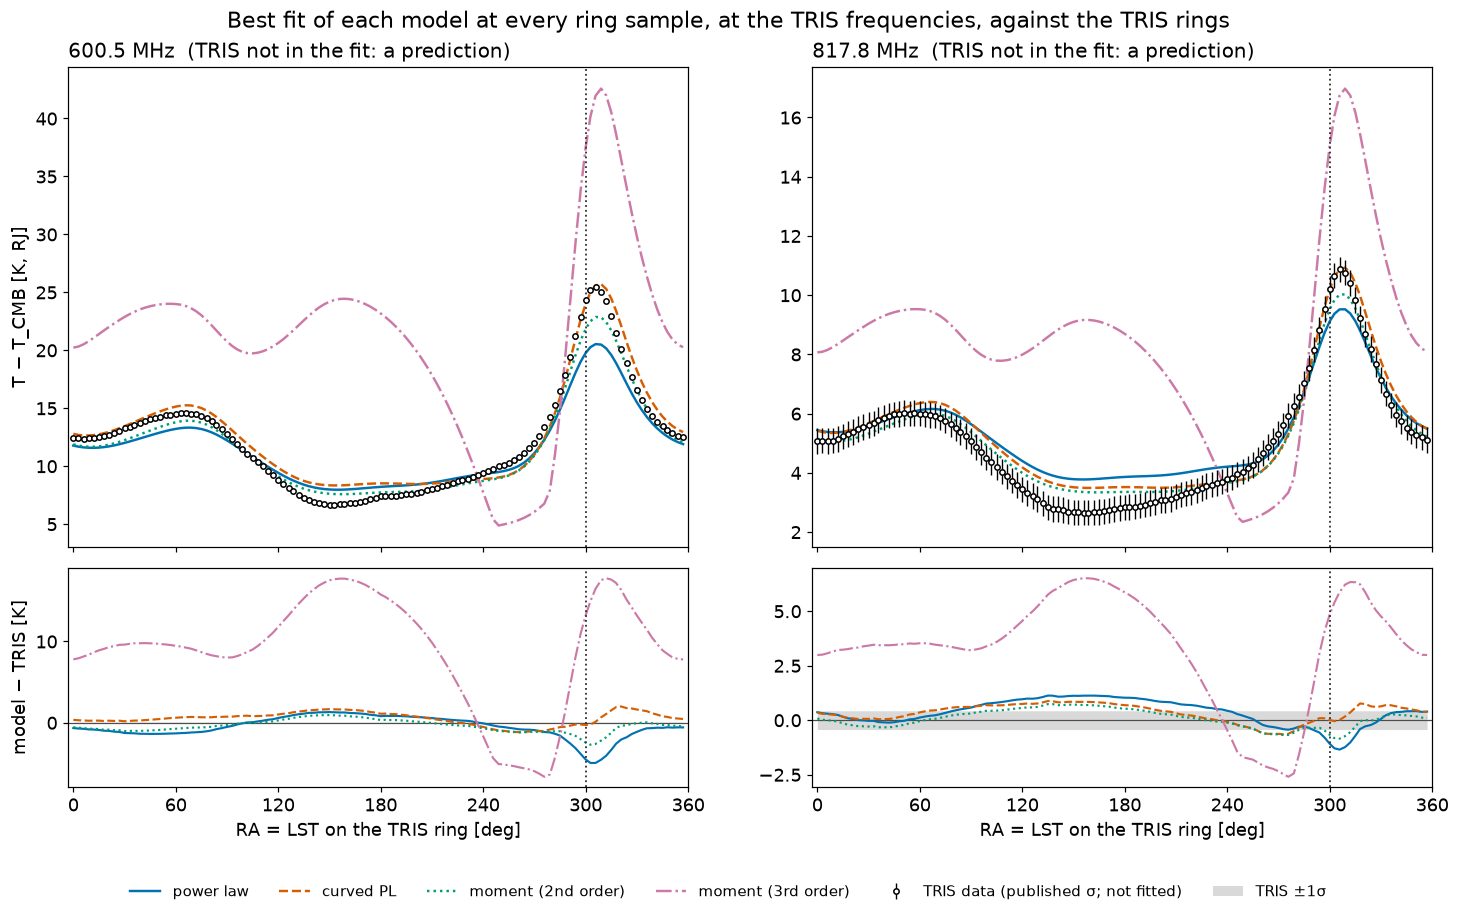

saved paper_outputs/model_comparison/diagnostic_plots/fig10_models_at_tris_frequencies.png
saved diagnostic_plots/part5_model_tods_at_tris.csv and part5_model_minus_tris_summary.csv

             model TRIS band  median (model − TRIS) [K]  rms [K]  max |model − TRIS| [K]  median |model − TRIS| / σ  samples with |model − TRIS| > σ
         power law 600.5 MHz                     -0.622    1.465                   4.952                     13.457                              117
         curved PL 600.5 MHz                      0.662    0.953                   1.994                     11.178                              118
moment (2nd order) 600.5 MHz                     -0.400    0.868                   2.711                      9.803                              111
moment (3rd order) 600.5 MHz                      9.566   11.166                  17.771                    143.110                              120
         power law 817.8 MHz                      0.382    0.684        

In [21]:
if not P5:
    print("Figure 10 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    TT5, SS5, NN5 = {}, {}, {}
    for k in TRIS_KEYS:
        if k in FITTED_TRIS:   # a fit point: exactly as fitted
            TT5[k] = np.array([PTS5[u][1][PTS5[u][3].index(k)] for u in ALL_UNITS])
            SS5[k] = np.array([PTS5[u][2][PTS5[u][3].index(k)] for u in ALL_UNITS])
            NN5[k] = float(PTS5[ALL_UNITS[0]][0][PTS5[ALL_UNITS[0]][3].index(k)])
        else:                  # not fitted: the TRIS ring from step 2 (as run_comparison.tod_units builds it), for comparison only
            NN5[k] = RING["nu"][k]
            TT5[k] = np.asarray(RING["T"][k], dtype=float)[ALL_UNITS]
            SS5[k] = np.asarray(RING["S"][k], dtype=float)[ALL_UNITS]
    MT5 = {(m, k): np.array([model_at(m, u, NN5[k])[0] for u in ALL_UNITS]) for m in MODELS for k in TRIS_KEYS}
    LS5 = {PL: "-", CURVED: "--", MOMENT: ":", MOMENT3: "-."}

    fig, axes = plt.subplots(2, max(len(TRIS_KEYS), 1), figsize=(8 * max(len(TRIS_KEYS), 1), 8.5), sharex=True,
                             squeeze=False, gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.06, wspace=0.2))
    rows, csv_cols = [], {"unit": ALL_UNITS, "RA [deg]": RA5}
    for c, k in enumerate(TRIS_KEYS):
        ax, ar = axes[0, c], axes[1, c]
        ax.errorbar(RA5, TT5[k], yerr=SS5[k], fmt="o", ms=3.5, color="black", elinewidth=0.9, capsize=0, zorder=3,
                    label="TRIS data (published σ)" if k in FITTED_TRIS else "TRIS data (published σ; not fitted)",
                    mfc="black" if k in FITTED_TRIS else "white")
        ar.fill_between(RA5, -SS5[k], SS5[k], color="0.85", lw=0, label="TRIS ±1σ")
        ar.axhline(0, color="0.3", lw=0.8)
        csv_cols[f"TRIS {NN5[k]:g} MHz [K]"] = TT5[k]; csv_cols[f"TRIS {NN5[k]:g} MHz σ [K]"] = SS5[k]
        for m in MODELS:
            d = MT5[(m, k)] - TT5[k]
            ax.plot(RA5, MT5[(m, k)], color=COL[m], ls=LS5[m], lw=1.6, label=SHORT[m])
            ar.plot(RA5, d, color=COL[m], ls=LS5[m], lw=1.4)
            csv_cols[f"{SHORT[m]} at {NN5[k]:g} MHz [K]"] = MT5[(m, k)]
            csv_cols[f"{SHORT[m]} − TRIS at {NN5[k]:g} MHz [K]"] = d
            rows.append({"model": SHORT[m], "TRIS band": f"{NN5[k]:g} MHz", "median (model − TRIS) [K]": np.median(d),
                         "rms [K]": np.sqrt(np.mean(d ** 2)), "max |model − TRIS| [K]": np.max(np.abs(d)),
                         "median |model − TRIS| / σ": np.median(np.abs(d) / SS5[k]),
                         "samples with |model − TRIS| > σ": int(np.sum(np.abs(d) > SS5[k]))})
        for a in (ax, ar):
            a.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        ax.set_title(f"{NN5[k]:g} MHz" + ("" if k in FITTED_TRIS else "  (TRIS not in the fit: a prediction)"), loc="left")
        ar.set_xlabel("RA = LST on the TRIS ring [deg]"); ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
    axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
    axes[1, 0].set_ylabel("model − TRIS [K]")
    h, l = axes[0, 0].get_legend_handles_labels(); h2, l2 = axes[1, 0].get_legend_handles_labels()
    fig.legend(h + h2, l + l2, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 0.02))
    fig.suptitle("Best fit of each model at every ring sample, at the TRIS frequencies, against the TRIS rings", y=0.94)
    save(fig, "fig10_models_at_tris_frequencies")
    pd.DataFrame(csv_cols).to_csv(PLOT_DIR / "part5_model_tods_at_tris.csv", index=False)
    t10 = pd.DataFrame(rows)
    t10.to_csv(PLOT_DIR / "part5_model_minus_tris_summary.csv", index=False)
    print("saved diagnostic_plots/part5_model_tods_at_tris.csv and part5_model_minus_tris_summary.csv\n")
    with pd.option_context("display.width", 200):
        print(t10.round(3).to_string(index=False))

#### Figure 11 — χ² of every fit

For each model and ring sample, χ² = Σ ((T − model)/σ)² over the sample's points at the best fit, with ν = N − k degrees
of freedom (N points, k parameters). **Top:** χ² along the ring; **bottom:** χ²/ν (order 3 has ν = N − 4). The tables
give, per model, the median, range and how many samples exceed χ²/ν = 1 and 2, and which points carry the χ² (median
share of χ² per input). χ² is not summed over samples: neighbouring samples are correlated. Saved to
`diagnostic_plots/part5_chi2_per_sample.csv` (with every point's contribution) and `part5_chi2_summary.csv`.

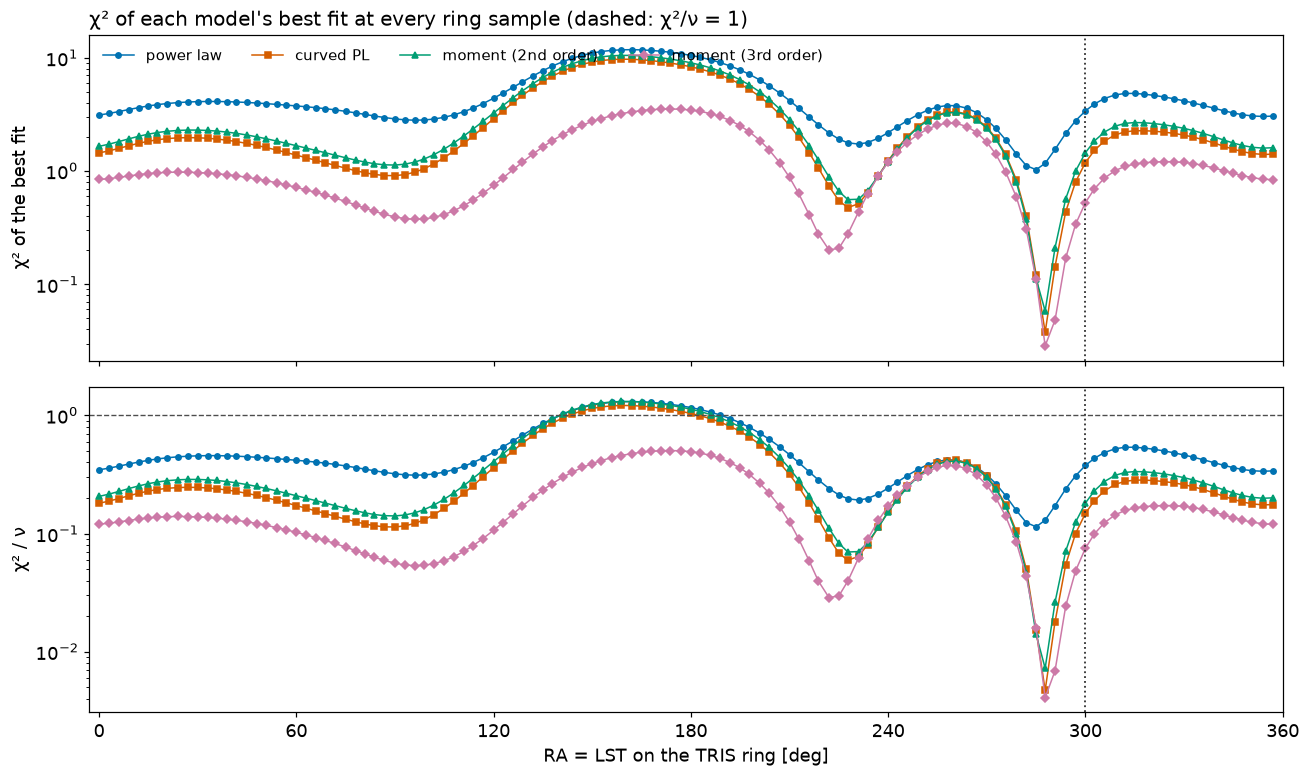

saved paper_outputs/model_comparison/diagnostic_plots/fig11_chi2_per_sample.png
saved diagnostic_plots/part5_chi2_summary.csv and part5_chi2_per_sample.csv

             model  parameters k points N ν = N − k  median χ²  mean $$\chi^2$$  min χ²  max χ²  RA of max [deg]  median χ²/ν  samples χ²/ν > 1  samples χ²/ν > 2
         power law             2       11         9      3.763            4.691   1.027  11.785           162.00        0.418                17                 0
         curved PL             3       11         8      1.891            2.949   0.038   9.713           158.75        0.236                13                 0
moment (2nd order)             3       11         8      2.170            3.252   0.058  10.495           158.75        0.271                16                 0
moment (3rd order)             4       11         7      0.952            1.282   0.029   3.531           173.75        0.136                 0                 0

median share of a sample's χ² fr

In [22]:
if not P5:
    print("Figure 11 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    MK5 = {PL: "o", CURVED: "s", MOMENT: "^", MOMENT3: "D"}
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(hspace=0.08))
    for m in MODELS:
        c2 = np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS])
        dof = np.array([CHI[(m, u)]["n"] - CHI[(m, u)]["k"] for u in ALL_UNITS])
        a1.plot(RA5, c2, MK5[m] + "-", color=COL[m], ms=3.5, lw=1, label=SHORT[m])
        a2.plot(RA5, np.where(dof > 0, c2 / np.maximum(dof, 1), np.nan), MK5[m] + "-", color=COL[m], ms=3.5, lw=1)
    for a in (a1, a2):
        a.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        a.set_yscale("log")
    a2.axhline(1, color="0.3", lw=0.9, ls="--")
    a1.set_ylabel("χ² of the best fit"); a2.set_ylabel("χ² / ν")
    a2.set_xlabel("RA = LST on the TRIS ring [deg]"); a2.set_xlim(-3, 360); a2.set_xticks(np.arange(0, 361, 60))
    a1.legend(frameon=False, ncol=4, loc="upper left")
    a1.set_title("χ² of each model's best fit at every ring sample (dashed: χ²/ν = 1)", loc="left")
    save(fig, "fig11_chi2_per_sample")

    rows, per = [], []
    for m in MODELS:
        c2 = np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS])
        n = np.array([CHI[(m, u)]["n"] for u in ALL_UNITS]); kpar = len(MODELS[m][0]); dof = n - kpar
        red = np.where(dof > 0, c2 / np.maximum(dof, 1), np.nan)
        rows.append({"model": SHORT[m], "parameters k": kpar, "points N": "/".join(map(str, sorted(set(n)))),
                     "ν = N − k": "/".join(map(str, sorted(set(dof)))), "median χ²": np.median(c2),
                     'mean '+r'$$\chi^2$$': np.mean(c2),
                     "min χ²": c2.min(), "max χ²": c2.max(), f"RA of max [deg]": RA5[np.argmax(c2)],
                     "median χ²/ν": np.nanmedian(red), "samples χ²/ν > 1": int(np.sum(red > 1)),
                     "samples χ²/ν > 2": int(np.sum(red > 2))})
        for u in ALL_UNITS:
            d = CHI[(m, u)]
            per.append({"unit": u, "RA [deg]": RA_OF[u], "model": SHORT[m], "N": d["n"], "k": d["k"], "ν": d["n"] - d["k"],
                        "χ²": d["chi2"], "χ²/ν": d["chi2"] / (d["n"] - d["k"]) if d["n"] > d["k"] else np.nan,
                        **{f"χ² from {POINT_NAMES.get(kk, kk)}": v for kk, v in d["contrib"].items()},
                        **{f"best-fit {nm}": v for nm, v in zip(MODELS[m][0], FIT5[m][u])}})
    t11 = pd.DataFrame(rows); t11p = pd.DataFrame(per)
    t11.to_csv(PLOT_DIR / "part5_chi2_summary.csv", index=False)
    t11p.to_csv(PLOT_DIR / "part5_chi2_per_sample.csv", index=False)
    print("saved diagnostic_plots/part5_chi2_summary.csv and part5_chi2_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t11.round(3).to_string(index=False))
    share = {}
    for m in MODELS:
        sub = t11p[t11p["model"] == SHORT[m]]
        cols = [c for c in sub.columns if c.startswith("χ² from ")]
        share[SHORT[m]] = (sub[cols].div(sub["χ²"], axis=0)).median() * 100
    print("\nmedian share of a sample's χ² from each input [%]:")
    print(pd.DataFrame(share).rename(index=lambda c: c.replace("χ² from ", "")).round(1).to_string())

    # Check: the minimum χ² here against UltraNest's own maximum likelihood (Part 2 reruns, same data key).
    if P2_UNITS:
        chk = []
        for u in P2_UNITS:
            for m in MODELS:
                r = P2[m][u]; s = np.asarray(r["s"], dtype=float)
                c2_un = -2 * (float(r["maxlogl"]) + np.sum(np.log(s * np.sqrt(2 * np.pi))))
                chk.append({"unit": u, "model": SHORT[m], "χ² here (L-BFGS-B)": CHI[(m, u)]["chi2"],
                            "χ² at UltraNest's max likelihood": c2_un, "difference": CHI[(m, u)]["chi2"] - c2_un})
        chk = pd.DataFrame(chk)
        print(f"\ncheck against UltraNest (Part 2 samples): χ² here − χ² at UltraNest's best point: "
              f"median {chk['difference'].median():+.3f}, range {chk['difference'].min():+.3f} to {chk['difference'].max():+.3f} "
              "(≤ 0 means the optimiser found an equal or better fit)")

## Part 6 — how robust is the verdict?

Six checks of the Part 1 verdict, all from results already on disk (the two comparison CSVs and the Part 5 maximum-likelihood
fits); nothing here reruns UltraNest or Parts 2–4. Only Figure 17 refits, and only with the maximum-likelihood fitter.

**Facts to keep in mind when reading every number below.**

* **4 points per fit.** Every ring sample is fitted with only LWA1 35, Maipu 45, LWA1 80 and Stockert 1420. TRIS 600 and
  820 are **not** in the fit (`comparison.exclude_tris`), so comparing the fits with TRIS (Figure 15) is a genuine held-out test.
* **Few degrees of freedom.** With N = 4 the power law (k = 2) has ν = 2, the curved power law and the order-2 moment
  expansion (k = 3) have ν = 1, and the order-3 moment expansion (k = 4) has ν = 0: it passes through every point.
  The small-sample AIC (AICc) divides by N − k − 1, which is ≤ 0 for k ≥ 3, so it is undefined here and only AIC and BIC
  are used. Leaving one point out would leave 3 points for 3–4 parameters, so leave-one-out prediction is not made.
* **Correlated samples.** Ring samples are 3° apart under a ~20° beam, so the counts are not 120 independent votes, no
  ln Z is summed over samples, and standard errors of means stacked over samples (Figure 16) are underestimates.
* **The Cygnus A mask is a decision, not a result.** The samples within `MASK_HALF_WIDTH` = 25° of Cygnus A (RA 299.9°)
  are excluded in the masked numbers because the sky there is too bright and structured to model reliably; `MASK_ALT` =
  15° is the narrower alternative. Every ring plot shades both windows (dark ±15°, light ±25°), and numbers are given
  with and without the mask.

In [23]:
# ---- Part 6 settings ----
MASK_HALF_WIDTH = 25.0     # deg: Cygnus A mask; samples with |RA − CYG_A_RA| <= this are excluded (a decision, not a result)
MASK_ALT = 15.0            # deg: the narrower alternative mask
BORDER = 0.4               # a Δ within this of ±TIE is "borderline"
IC_TIE = 2.0               # |ΔAIC|, |ΔBIC|, |Δχ²| <= 2: indistinguishable
SYS_NSE = 3.0              # Figure 16: |mean residual| > SYS_NSE standard errors ...
SYS_FRAC = 0.75            # ... and at least SYS_FRAC of the samples share its sign -> "systematic"
ERR_SCALES = (0.7, 1.5)    # Figure 17: the errors of all fit points multiplied by these (1.0 = Part 5)
RUN_ERR_SENS = True        # Figure 17: refit every model at every sample at each scale (maximum likelihood, cached)
EXTRA = (CURVED, MOMENT, MOMENT3)   # the extra-parameter models, each compared with the power law

def cyg_dist(r):
    # distance from Cygnus A in RA [deg], wrapping at 360
    return np.abs((np.asarray(r, dtype=float) - CYG_A_RA + 180.0) % 360.0 - 180.0)

def keep(r, half):
    # samples kept under a mask of half-width `half` [deg]; None keeps all
    r = np.asarray(r, dtype=float)
    return np.ones(r.shape, bool) if half is None else cyg_dist(r) > half

MASKS = {"all samples": None, f"excl. ±{MASK_ALT:g}°": MASK_ALT, f"excl. ±{MASK_HALF_WIDTH:g}°": MASK_HALF_WIDTH}

def shade_mask(ax, label=False):
    ax.axvspan(CYG_A_RA - MASK_HALF_WIDTH, CYG_A_RA + MASK_HALF_WIDTH, color="0.94", lw=0, zorder=0,
               label=f"Cygnus mask ±{MASK_HALF_WIDTH:g}°" if label else None)
    ax.axvspan(CYG_A_RA - MASK_ALT, CYG_A_RA + MASK_ALT, color="0.84", lw=0, zorder=0,
               label=f"Cygnus mask ±{MASK_ALT:g}°" if label else None)

def ring_axis(ax):
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))

BORDER_COL = f"borderline (within {BORDER:g} of ±{TIE:g})"
def classify(d):
    # Δ = score(model) − score(power law): > TIE favours the model, < −TIE the power law
    d = np.asarray(d, dtype=float)
    return {"favours model": int((d > TIE).sum()), "tie": int((np.abs(d) <= TIE).sum()),
            "favours power law": int((d < -TIE).sum()), BORDER_COL: int((np.abs(np.abs(d) - TIE) <= BORDER).sum())}

def classify_ic(d):
    # Δ = criterion(model) − criterion(power law): lower is better, so < −IC_TIE favours the model
    d = np.asarray(d, dtype=float)
    return {"favours model": int((d < -IC_TIE).sum()), "indistinguishable": int((np.abs(d) <= IC_TIE).sum()),
            "favours power law": int((d > IC_TIE).sum())}

# Both comparison runs (evidence and maximum likelihood), joined on the ring-sample index.
J = None
if not (EV_CSV.exists() and ML_CSV.exists()):
    print("Part 6: Figures 12 (table) and 13 need both", EV_CSV.relative_to(REPO), "and", ML_CSV.relative_to(REPO),
          "- missing:", [p.name for p in (EV_CSV, ML_CSV) if not p.exists()])
else:
    _e, _m = pd.read_csv(EV_CSV), pd.read_csv(ML_CSV)
    assert len(_e) == len(_m) == len(ALL_UNITS_RING) and set(_e["unit"]) == set(_m["unit"]) == set(ALL_UNITS_RING), \
        "the evidence and max-likelihood CSVs do not cover the same ring samples"
    J = _e.merge(_m, on="unit", suffixes=(" (ev)", " (ml)")).sort_values("unit").reset_index(drop=True)
    _same = bool((J["n_points (ev)"] == J["n_points (ml)"]).all() and (J["inputs (ev)"] == J["inputs (ml)"]).all())
    if not _same:
        print("WARNING: the evidence and max-likelihood runs used different data at",
              int(((J["n_points (ev)"] != J["n_points (ml)"]) | (J["inputs (ev)"] != J["inputs (ml)"])).sum()),
              "samples; Figure 13 compares them anyway")
    RA6 = J["ra_deg (ev)"].to_numpy()
    DZ = {m: (J[f"logZ {m}"] - J[f"logZ {PL}"]).to_numpy() for m in EXTRA}      # Δ ln Z (Occam penalty included)
    DL = {m: (J[f"lnLmax {m}"] - J[f"lnLmax {PL}"]).to_numpy() for m in EXTRA}  # Δ ln L_max (no Occam penalty)
    import datetime
    _mt = lambda p: datetime.datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
    print(f"Part 6: {len(J)} ring samples in both runs; same data in both: {_same}")
    print(f"  evidence run       {EV_CSV.relative_to(REPO)} ({_mt(EV_CSV)}): inputs {sorted(J['inputs (ev)'].unique())}")
    print(f"  max-likelihood run {ML_CSV.relative_to(REPO)} ({_mt(ML_CSV)}): inputs {sorted(J['inputs (ml)'].unique())}")
for _lab, _h in MASKS.items():
    print(f"  {_lab}: {int(keep(np.array([RA_OF[u] for u in ALL_UNITS_RING]), _h).sum())} samples")

Part 6: 120 ring samples in both runs; same data in both: False
  evidence run       paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv (2026-11-16 19:55): inputs ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
  max-likelihood run paper_outputs/pipeline/step3_model_comparison/maxlike_per_unit_tod.csv (2026-10-28 19:03): inputs ['LWA_35MHz.fits;MAIPU_45mhZ.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
  all samples: 120 samples
  excl. ±15°: 110 samples
  excl. ±25°: 103 samples


#### Figure 12 — Figure 1 with the Cygnus A mask

Δ score along the ring for the curved power law and the moment expansion (orders 2 and 3), each against the power law, as in
Figure 1 (the score is the run's statistic, `SC`). The shaded windows are the Cygnus A masks (dark ±15°, light ±25°); samples
inside ±25° are drawn in grey. Solid horizontal lines mark ±1 (the tie band lies between them), dashed lines ±2. The boxes
give the counts with and without the mask. The table counts, for **both** statistics (ΔlnZ from the evidence run, ΔlnL_max
from the max-likelihood run, with the same thresholds), how often the model or the power law is favoured, how often they tie,
and how often Δ is borderline (within 0.4 of ±1), for all samples and for the two masks. Saved to
`diagnostic_plots/part6_counts_masked.csv`.

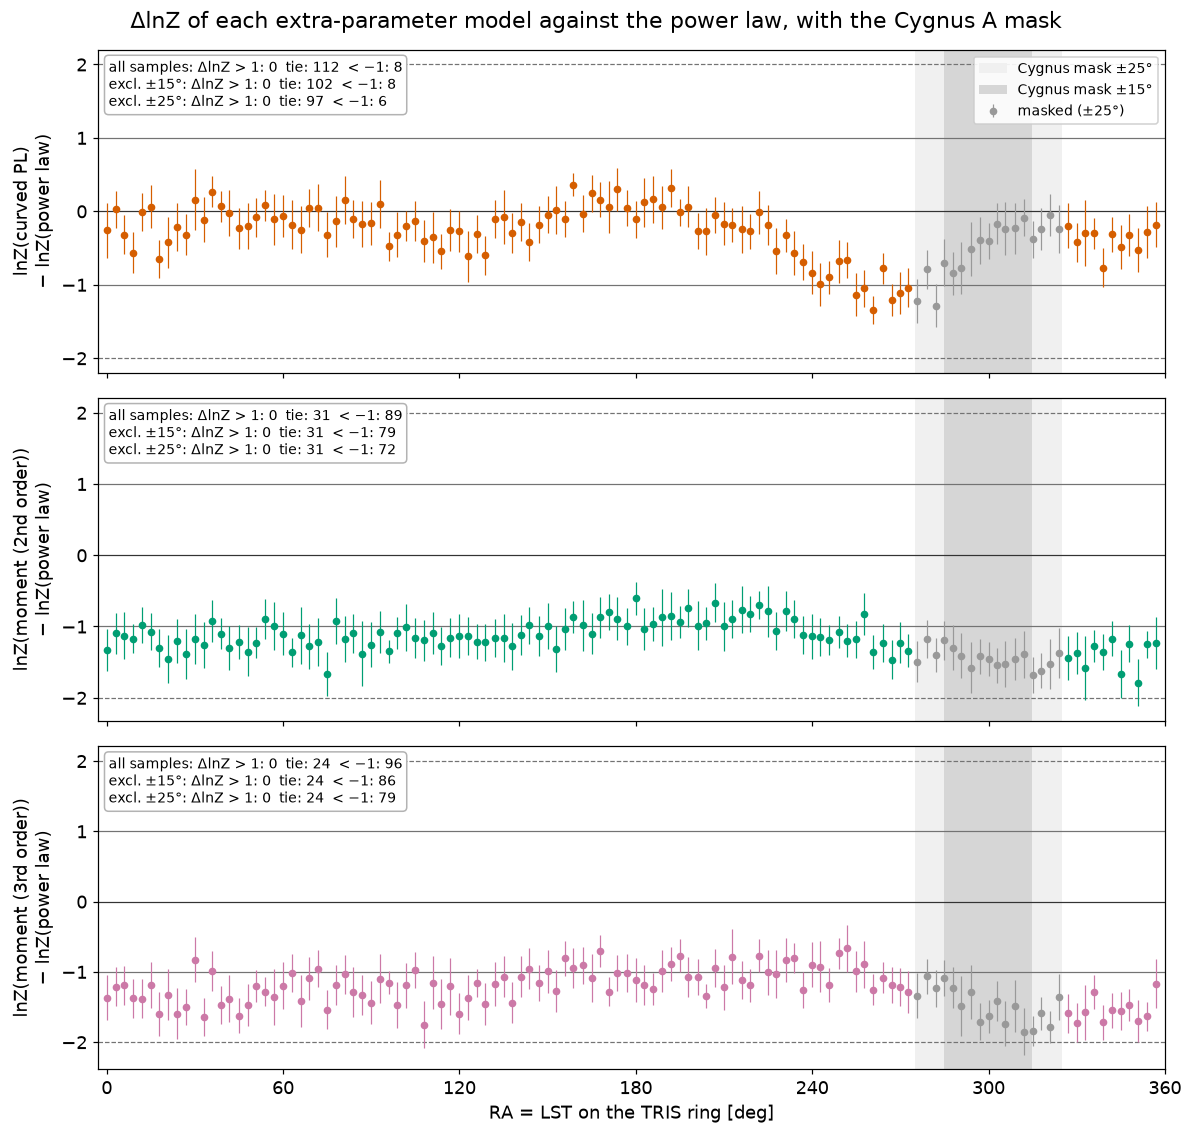

saved paper_outputs/model_comparison/diagnostic_plots/fig12_dscore_vs_ra_masked.png
saved diagnostic_plots/part6_counts_masked.csv

                statistic                      comparison     samples   n  favours model  tie  favours power law  borderline (within 0.4 of ±1)
          evidence (ΔlnZ)          curved PL vs power law all samples 120              0  112                  8                             22
          evidence (ΔlnZ)          curved PL vs power law  excl. ±15° 110              0  102                  8                             19
          evidence (ΔlnZ)          curved PL vs power law  excl. ±25° 103              0   97                  6                             16
          evidence (ΔlnZ) moment (2nd order) vs power law all samples 120              0   31                 89                            102
          evidence (ΔlnZ) moment (2nd order) vs power law  excl. ±15° 110              0   31                 79                             99
    

In [24]:
if not P1:
    print("Figure 12 skipped: no comparison CSV for Part 1.")
else:
    km = keep(ra, MASK_HALF_WIDTH)
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, d, e, m in zip(axes, (dC, dM, dM3), (dC_err, dM_err, dM3_err), EXTRA):
        shade_mask(ax, label=(m == CURVED))
        for y, ls in ((TIE, "-"), (-TIE, "-"), (STRONG, "--"), (-STRONG, "--")):
            ax.axhline(y, color="0.45", lw=0.8, ls=ls)
        ax.axhline(0, color="0.2", lw=0.8)
        ax.errorbar(ra[km], d[km], yerr=None if ML_STAT else e[km], fmt="o", ms=4, color=COL[m], elinewidth=0.8, capsize=0)
        ax.errorbar(ra[~km], d[~km], yerr=None if ML_STAT else e[~km], fmt="o", ms=4, color="0.6", elinewidth=0.8,
                    capsize=0, label=f"masked (±{MASK_HALF_WIDTH:g}°)" if m == CURVED else None)
        txt = "\n".join(f"{lab}: {DSC} > 1: {c['favours model']}  tie: {c['tie']}  < −1: {c['favours power law']}"
                        for lab, h in MASKS.items() for c in [classify(d[keep(ra, h)])])
        ax.text(0.01, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
        ax.set_ylabel(f"{SC}({SHORT[m]})\n− {SC}(power law)")
    axes[0].legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=9)
    ring_axis(axes[-1])
    fig.suptitle(f"{DSC} of each extra-parameter model against the power law, with the Cygnus A mask")
    fig.tight_layout()
    save(fig, "fig12_dscore_vs_ra_masked")

if J is None:
    print("Table for Figure 12 skipped: needs both comparison CSVs.")
else:
    rows = []
    for stat, D in (("evidence (ΔlnZ)", DZ), ("max likelihood (ΔlnL_max)", DL)):
        for m in EXTRA:
            for lab, h in MASKS.items():
                k_ = keep(RA6, h)
                rows.append({"statistic": stat, "comparison": f"{SHORT[m]} vs power law", "samples": lab,
                             "n": int(k_.sum()), **classify(D[m][k_])})
    t12 = pd.DataFrame(rows)
    t12.to_csv(PLOT_DIR / "part6_counts_masked.csv", index=False)
    print("saved diagnostic_plots/part6_counts_masked.csv\n")
    with pd.option_context("display.width", 220):
        print(t12.to_string(index=False))

#### Figure 13 — how much of the evidence difference is the Occam penalty?

For every ring sample (all 120, not only the Part 2 reruns). **Top:** for each extra-parameter model, ΔlnZ against the power
law (y, evidence run, Occam penalty included) against ΔlnL_max (x, max-likelihood run: the gain in best fit, no penalty).
Points are coloured by RA (a cyclic colour scale); samples inside the ±25° Cygnus mask have a black edge. On the dashed 1:1
line the evidence would follow the fit exactly; the vertical distance below it is the Occam penalty. The grey band is the
±1 tie range in ΔlnZ. **Bottom:** the Occam penalty per sample, ΔlnL_max − ΔlnZ, along the ring, with the masks shaded.
Both CSVs are joined on the sample index. Saved to `diagnostic_plots/part6_occam_penalty.csv` (per sample) and
`part6_occam_penalty_summary.csv`.

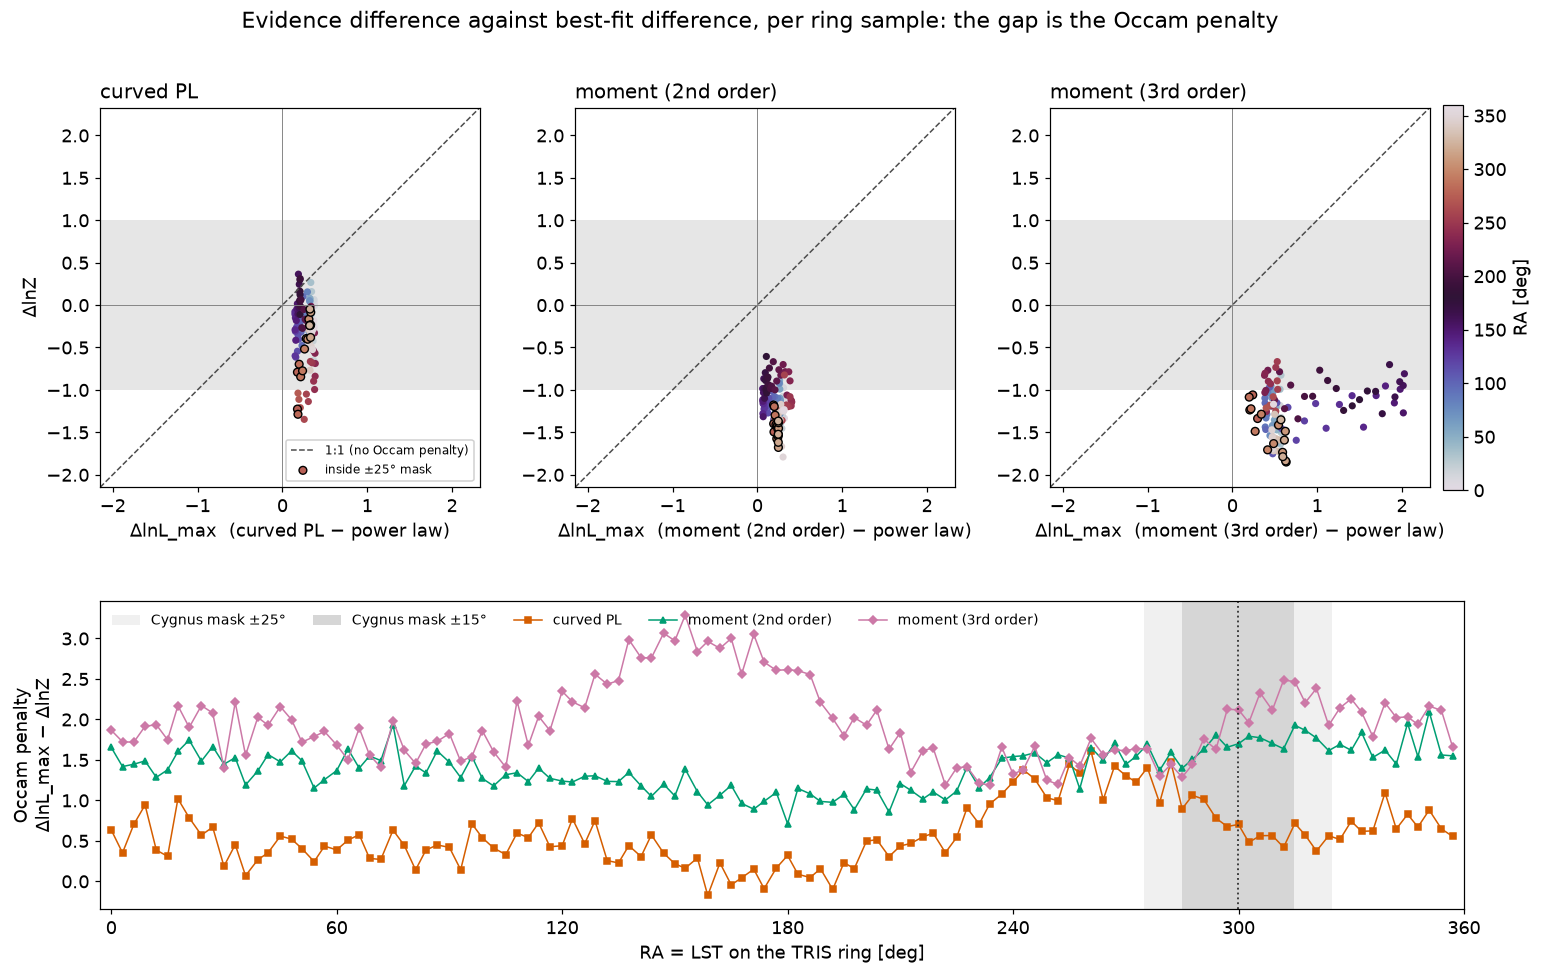

saved paper_outputs/model_comparison/diagnostic_plots/fig13_occam_penalty.png
saved diagnostic_plots/part6_occam_penalty.csv and part6_occam_penalty_summary.csv

             model     samples   n  median ΔlnL_max  median ΔlnZ  median Occam penalty  min Occam penalty  max Occam penalty  samples ΔlnL_max > 1  samples ΔlnZ > 1
         curved PL all samples 120            0.301       -0.242                 0.538             -0.175              1.605                     0                 0
         curved PL  excl. ±15° 110            0.304       -0.238                 0.515             -0.175              1.605                     0                 0
         curved PL  excl. ±25° 103            0.303       -0.201                 0.496             -0.175              1.605                     0                 0
moment (2nd order) all samples 120            0.247       -1.173                 1.414              0.712              2.094                     0                 0
moment (2nd o

In [25]:
if J is None:
    print("Figure 13 skipped: needs both", EV_CSV.name, "and", ML_CSV.name)
else:
    from matplotlib.gridspec import GridSpec
    inm = ~keep(RA6, MASK_HALF_WIDTH)
    fig = plt.figure(figsize=(16, 9.5))
    gs = GridSpec(2, 3, figure=fig, height_ratios=[1.25, 1], hspace=0.32, wspace=0.25)
    lo = min(min(DL[m].min(), DZ[m].min()) for m in EXTRA) - 0.3
    hi = max(max(DL[m].max(), DZ[m].max()) for m in EXTRA) + 0.3
    for j, m in enumerate(EXTRA):
        ax = fig.add_subplot(gs[0, j])
        ax.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
        ax.plot([lo, hi], [lo, hi], color="0.3", ls="--", lw=1, label="1:1 (no Occam penalty)")
        ax.axhline(0, color="0.5", lw=0.6); ax.axvline(0, color="0.5", lw=0.6)
        sc = ax.scatter(DL[m][~inm], DZ[m][~inm], c=RA6[~inm], cmap="twilight", vmin=0, vmax=360, s=22, lw=0)
        ax.scatter(DL[m][inm], DZ[m][inm], c=RA6[inm], cmap="twilight", vmin=0, vmax=360, s=26, edgecolors="black",
                   linewidths=0.9, label=f"inside ±{MASK_HALF_WIDTH:g}° mask")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        ax.set_xlabel(f"ΔlnL_max  ({SHORT[m]} − power law)")
        ax.set_ylabel("ΔlnZ" if j == 0 else "")
        ax.set_title(SHORT[m], loc="left")
        if j == 0:
            ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
    cb = fig.colorbar(sc, ax=[fig.axes[0], fig.axes[1], fig.axes[2]], fraction=0.015, pad=0.01)
    cb.set_label("RA [deg]")
    ax = fig.add_subplot(gs[1, :])
    shade_mask(ax, label=True)
    MK6 = {CURVED: "s", MOMENT: "^", MOMENT3: "D"}
    for m in EXTRA:
        ax.plot(RA6, DL[m] - DZ[m], MK6[m] + "-", color=COL[m], ms=3.5, lw=1, label=SHORT[m])
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
    ax.set_ylabel("Occam penalty\nΔlnL_max − ΔlnZ"); ring_axis(ax)
    ax.legend(ncol=5, loc="upper left", frameon=False, fontsize=9)
    fig.suptitle("Evidence difference against best-fit difference, per ring sample: the gap is the Occam penalty", y=0.97)
    save(fig, "fig13_occam_penalty")

    per = pd.DataFrame({"unit": J["unit"], "RA [deg]": RA6, f"inside ±{MASK_ALT:g}°": ~keep(RA6, MASK_ALT),
                        f"inside ±{MASK_HALF_WIDTH:g}°": inm})
    rows = []
    for m in EXTRA:
        per[f"ΔlnL_max {SHORT[m]}"] = DL[m]; per[f"ΔlnZ {SHORT[m]}"] = DZ[m]; per[f"Occam penalty {SHORT[m]}"] = DL[m] - DZ[m]
        for lab, h in MASKS.items():
            k_ = keep(RA6, h); oc = (DL[m] - DZ[m])[k_]
            rows.append({"model": SHORT[m], "samples": lab, "n": int(k_.sum()), "median ΔlnL_max": np.median(DL[m][k_]),
                         "median ΔlnZ": np.median(DZ[m][k_]), "median Occam penalty": np.median(oc),
                         "min Occam penalty": oc.min(), "max Occam penalty": oc.max(),
                         "samples ΔlnL_max > 1": int((DL[m][k_] > TIE).sum()), "samples ΔlnZ > 1": int((DZ[m][k_] > TIE).sum())})
    t13 = pd.DataFrame(rows)
    per.to_csv(PLOT_DIR / "part6_occam_penalty.csv", index=False)
    t13.to_csv(PLOT_DIR / "part6_occam_penalty_summary.csv", index=False)
    print("saved diagnostic_plots/part6_occam_penalty.csv and part6_occam_penalty_summary.csv\n")
    with pd.option_context("display.width", 220):
        print(t13.round(3).to_string(index=False))

#### Figure 14 — information criteria (AIC and BIC)

From the Part 5 best fits: AIC = χ² + 2k and BIC = χ² + k ln N, with N = 4 points and k = 2 (power law), 3 (curved power
law, moment order 2) or 4 (moment order 3). Each panel shows ΔAIC (solid) and ΔBIC (dashed), extra-parameter model minus power
law, along the ring; **below zero favours the extra-parameter model**. Dashed horizontal lines at ±2 bound the
"indistinguishable" range. The masks are shaded. AICc is undefined at this N (N − k − 1 ≤ 0 for k ≥ 3), and with only 4
points both criteria are crude: an extra parameter costs a fixed 2 (AIC) or ln 4 ≈ 1.39 (BIC) in χ². Saved to
`diagnostic_plots/part6_information_criteria_counts.csv` and `part6_information_criteria_per_sample.csv`.

points per sample N = [np.int64(11)]; k = power law 2, curved PL 3, moment (2nd order) 3, moment (3rd order) 4; AICc undefined for k >= N - 1


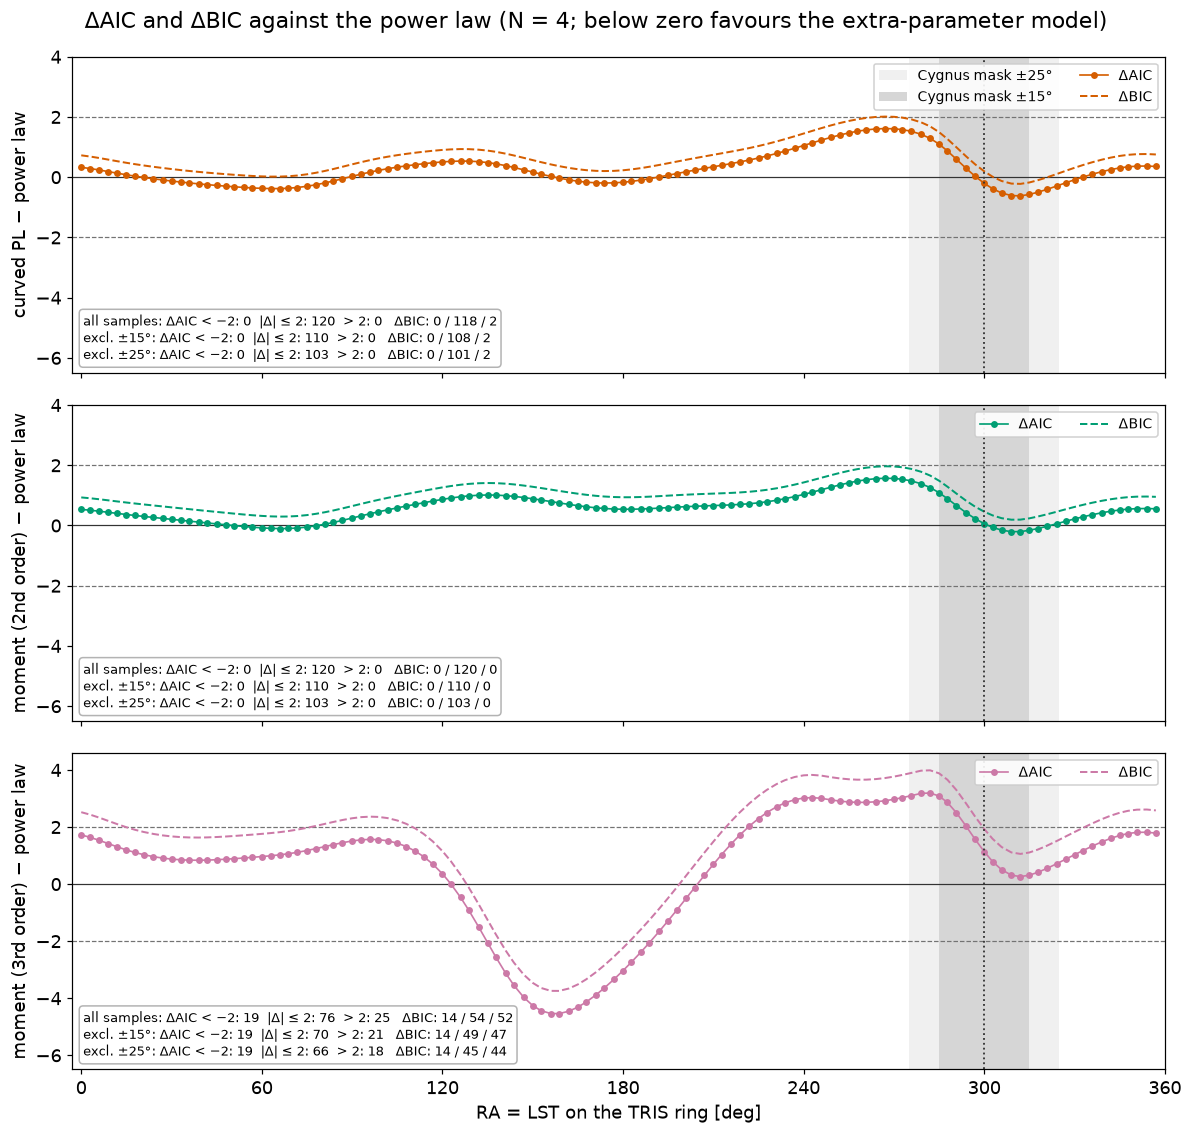

saved paper_outputs/model_comparison/diagnostic_plots/fig14_information_criteria.png
saved diagnostic_plots/part6_information_criteria_counts.csv and part6_information_criteria_per_sample.csv

criterion                      comparison     samples   n  favours model  indistinguishable  favours power law  median Δ
      AIC          curved PL vs power law all samples 120              0                120                  0      0.17
      AIC          curved PL vs power law  excl. ±15° 110              0                110                  0      0.18
      AIC          curved PL vs power law  excl. ±25° 103              0                103                  0      0.18
      AIC moment (2nd order) vs power law all samples 120              0                120                  0      0.56
      AIC moment (2nd order) vs power law  excl. ±15° 110              0                110                  0      0.56
      AIC moment (2nd order) vs power law  excl. ±25° 103              0         

In [26]:
if not P5:
    print("Figure 14 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    C2 = {m: np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS]) for m in MODELS}
    NPT = np.array([CHI[(PL, u)]["n"] for u in ALL_UNITS])
    KPAR = {m: len(MODELS[m][0]) for m in MODELS}
    AIC = {m: C2[m] + 2 * KPAR[m] for m in MODELS}
    BIC = {m: C2[m] + KPAR[m] * np.log(NPT) for m in MODELS}
    dAIC = {m: AIC[m] - AIC[PL] for m in EXTRA}; dBIC = {m: BIC[m] - BIC[PL] for m in EXTRA}
    print(f"points per sample N = {sorted(set(NPT))}; k = " + ", ".join(f"{SHORT[m]} {KPAR[m]}" for m in MODELS)
          + "; AICc undefined for k >= N - 1")
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, m in zip(axes, EXTRA):
        shade_mask(ax, label=(m == CURVED))
        for y in (IC_TIE, -IC_TIE):
            ax.axhline(y, color="0.45", lw=0.8, ls="--")
        ax.axhline(0, color="0.2", lw=0.8)
        ax.plot(RA5, dAIC[m], "o-", color=COL[m], ms=3.5, lw=1.1, label="ΔAIC")
        ax.plot(RA5, dBIC[m], "--", color=COL[m], lw=1.3, label="ΔBIC")
        ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        txt = "\n".join(f"{lab}: ΔAIC < −2: {a['favours model']}  |Δ| ≤ 2: {a['indistinguishable']}  > 2: {a['favours power law']}"
                        f"   ΔBIC: {b['favours model']} / {b['indistinguishable']} / {b['favours power law']}"
                        for lab, h in MASKS.items() for a, b in [(classify_ic(dAIC[m][keep(RA5, h)]), classify_ic(dBIC[m][keep(RA5, h)]))])
        ax.text(0.01, 0.03, txt, transform=ax.transAxes, va="bottom", fontsize=8.5,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"), zorder=5)
        ax.set_ylim(-6.5, max(4.0, 1.15 * max(dAIC[m].max(), dBIC[m].max())))
        ax.set_ylabel(f"{SHORT[m]} − power law")
        ax.legend(loc="upper right", fontsize=9, frameon=True, framealpha=0.9, ncol=2)
    ring_axis(axes[-1])
    fig.suptitle("ΔAIC and ΔBIC against the power law (N = 4; below zero favours the extra-parameter model)")
    fig.tight_layout()
    save(fig, "fig14_information_criteria")

    rows = []
    for crit, D in (("AIC", dAIC), ("BIC", dBIC)):
        for m in EXTRA:
            for lab, h in MASKS.items():
                k_ = keep(RA5, h)
                rows.append({"criterion": crit, "comparison": f"{SHORT[m]} vs power law", "samples": lab, "n": int(k_.sum()),
                             **classify_ic(D[m][k_]), "median Δ": np.median(D[m][k_])})
    t14 = pd.DataFrame(rows)
    per = pd.DataFrame({"unit": ALL_UNITS, "RA [deg]": RA5, "N": NPT,
                        **{f"ΔAIC {SHORT[m]}": dAIC[m] for m in EXTRA}, **{f"ΔBIC {SHORT[m]}": dBIC[m] for m in EXTRA}})
    t14.to_csv(PLOT_DIR / "part6_information_criteria_counts.csv", index=False)
    per.to_csv(PLOT_DIR / "part6_information_criteria_per_sample.csv", index=False)
    print("saved diagnostic_plots/part6_information_criteria_counts.csv and part6_information_criteria_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t14.round(2).to_string(index=False))

#### Figure 15 — held-out prediction at TRIS 600 and 820 MHz

For each model's best fit (Part 5, the arrays behind Figure 10; nothing is refitted), the standardised miss
z = (model − TRIS) / σ_TRIS at both TRIS bands for every ring sample, with σ_TRIS the published uncertainty (statistical ⊕
zero level). Because TRIS is not in the fit, this is a **true prediction**: the models never saw these data. **Top:** the
distribution of z over the ring per model (box: quartiles; whiskers: 1.5 × the interquartile range; dots: further samples).
**Bottom:** z along the ring with the masks shaded. The y axis is linear within ±1 and logarithmic beyond (z spans more
than two decades). |z| ≤ 1 (dashed lines) is within the TRIS uncertainty. Saved to `diagnostic_plots/part6_tris_prediction_z.csv`
(summary) and `part6_tris_prediction_z_per_sample.csv`.

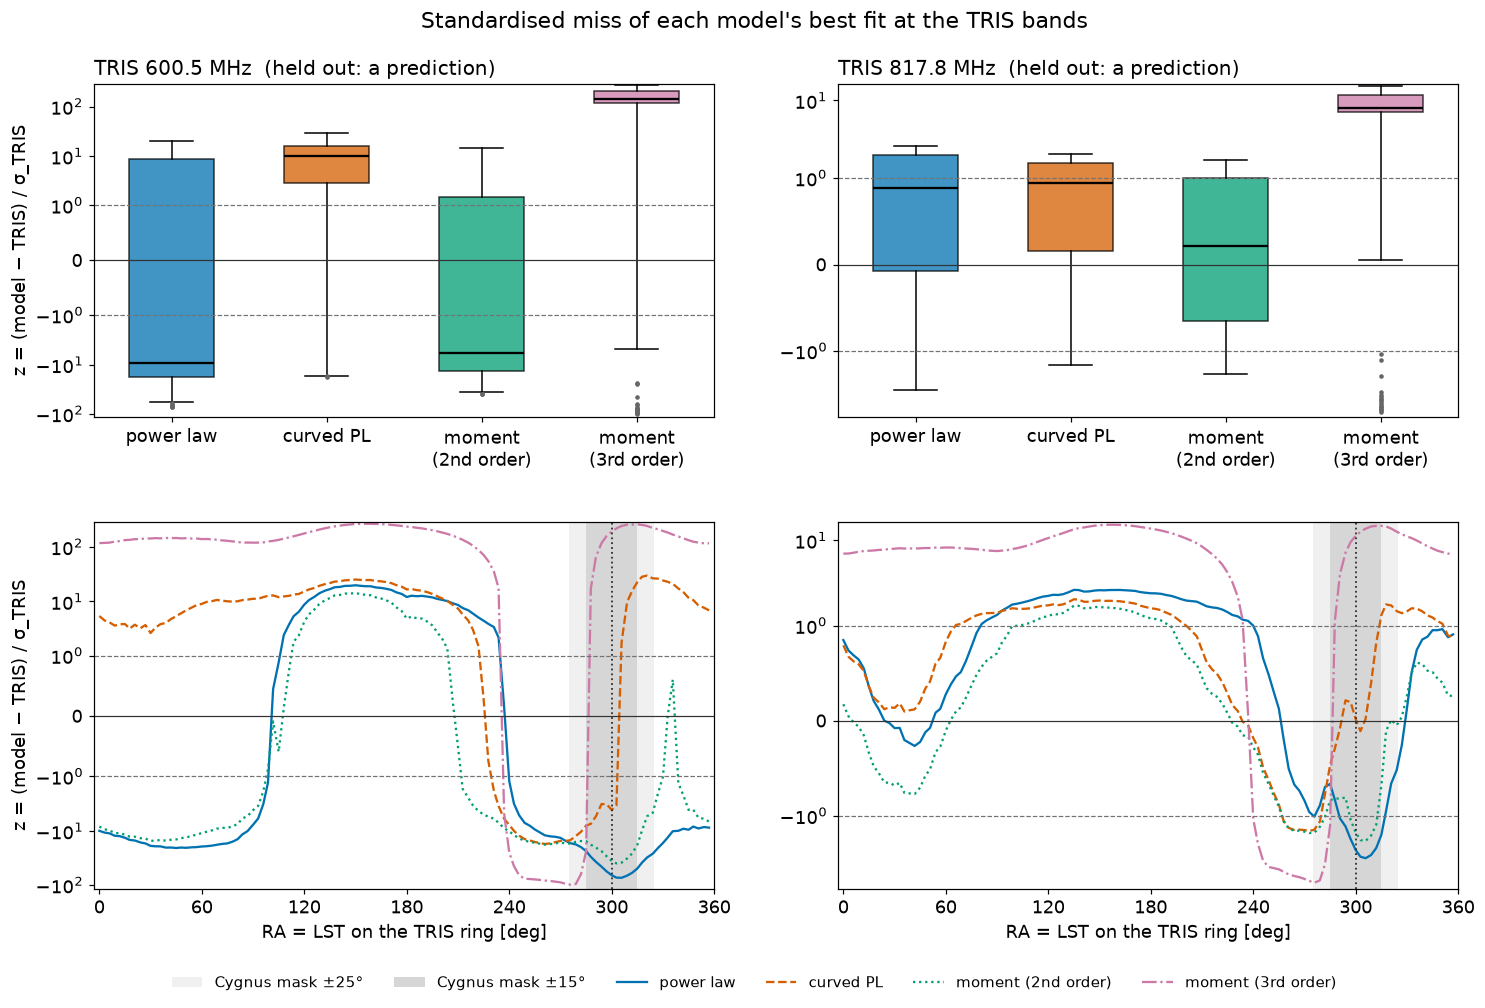

saved paper_outputs/model_comparison/diagnostic_plots/fig15_tris_prediction_z.png
saved diagnostic_plots/part6_tris_prediction_z.csv and part6_tris_prediction_z_per_sample.csv

TRIS band  held out              model     samples   n  median z   rms z  median |z|  samples |z| <= 1
600.5 MHz      True          power law all samples 120    -9.312  21.644      13.457                 3
600.5 MHz      True          power law  excl. ±15° 110    -8.199  15.157      12.624                 3
600.5 MHz      True          power law  excl. ±25° 103    -5.922  13.477      12.322                 3
600.5 MHz      True          curved PL all samples 120     9.833  14.281      11.178                 2
600.5 MHz      True          curved PL  excl. ±15° 110    10.123  14.750      12.088                 2
600.5 MHz      True          curved PL  excl. ±25° 103    10.082  14.123      11.597                 2
600.5 MHz      True moment (2nd order) all samples 120    -5.952  12.857       9.803                 9

In [27]:
if not P5 or "MT5" not in globals():
    print("Figure 15 skipped: needs the Part 5 fits and Figure 10's arrays (set RUN_ML_FITS = True and run Part 5).")
else:
    Z15 = {(m, k): (MT5[(m, k)] - TT5[k]) / SS5[k] for m in MODELS for k in TRIS_KEYS}
    fig, axes = plt.subplots(2, len(TRIS_KEYS), figsize=(8 * len(TRIS_KEYS), 9.5), squeeze=False,
                             gridspec_kw=dict(height_ratios=[1, 1.1], hspace=0.3, wspace=0.2))
    for c, k in enumerate(TRIS_KEYS):
        held = k not in FITTED_TRIS
        ax, ar = axes[0, c], axes[1, c]
        bp = ax.boxplot([Z15[(m, k)] for m in MODELS], patch_artist=True, widths=0.55,
                        flierprops=dict(marker="o", ms=3, mfc="0.4", mec="none"), medianprops=dict(color="black", lw=1.5))
        for patch, m in zip(bp["boxes"], MODELS):
            patch.set_facecolor(COL[m]); patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels([SHORT[m].replace(" (", "\n(") for m in MODELS])
        shade_mask(ar, label=(c == 0))
        for m in MODELS:
            ar.plot(RA5, Z15[(m, k)], color=COL[m], ls=LS5[m], lw=1.5, label=SHORT[m])
        ar.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2); ring_axis(ar)
        for a in (ax, ar):
            a.set_yscale("symlog", linthresh=1.0)
            a.axhline(0, color="0.2", lw=0.8)
            for y in (-1, 1):
                a.axhline(y, color="0.45", lw=0.8, ls="--")
        ax.set_title(f"TRIS {NN5[k]:g} MHz" + ("  (held out: a prediction)" if held else "  (in the fit: not a prediction)"), loc="left")
    axes[0, 0].set_ylabel("z = (model − TRIS) / σ_TRIS"); axes[1, 0].set_ylabel("z = (model − TRIS) / σ_TRIS")
    h, l = axes[1, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 0.04))
    fig.suptitle("Standardised miss of each model's best fit at the TRIS bands", y=0.95)
    save(fig, "fig15_tris_prediction_z")

    rows = []
    for k in TRIS_KEYS:
        for m in MODELS:
            for lab, h in MASKS.items():
                k_ = keep(RA5, h); zz = Z15[(m, k)][k_]
                rows.append({"TRIS band": f"{NN5[k]:g} MHz", "held out": k not in FITTED_TRIS, "model": SHORT[m],
                             "samples": lab, "n": int(k_.sum()), "median z": np.median(zz), "rms z": np.sqrt(np.mean(zz ** 2)),
                             "median |z|": np.median(np.abs(zz)), "samples |z| <= 1": int((np.abs(zz) <= 1).sum())})
    t15 = pd.DataFrame(rows)
    per = pd.DataFrame({"unit": ALL_UNITS, "RA [deg]": RA5,
                        **{f"z {SHORT[m]} at {NN5[k]:g} MHz": Z15[(m, k)] for k in TRIS_KEYS for m in MODELS}})
    t15.to_csv(PLOT_DIR / "part6_tris_prediction_z.csv", index=False)
    per.to_csv(PLOT_DIR / "part6_tris_prediction_z_per_sample.csv", index=False)
    print("saved diagnostic_plots/part6_tris_prediction_z.csv and part6_tris_prediction_z_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t15.round(3).to_string(index=False))

#### Figure 16 — stacked signed residuals against frequency

For each model's best fit (Part 5), the standardised residual (data − model)/σ of each fit point, averaged over the ring
samples: dots are the mean, bars the standard error std/√n (an **underestimate**, since neighbouring samples are correlated).
Filled markers use all samples, open markers exclude the ±25° Cygnus mask. A survey is marked as **systematic** (star, label
"S") when |mean| > 3 standard errors **and** at least 75% of the samples have the same sign. One panel per model; x is the
survey frequency. The residuals are recomputed from the cached best-fit parameters at each fitted point. Saved to
`diagnostic_plots/part6_stacked_residuals.csv`.

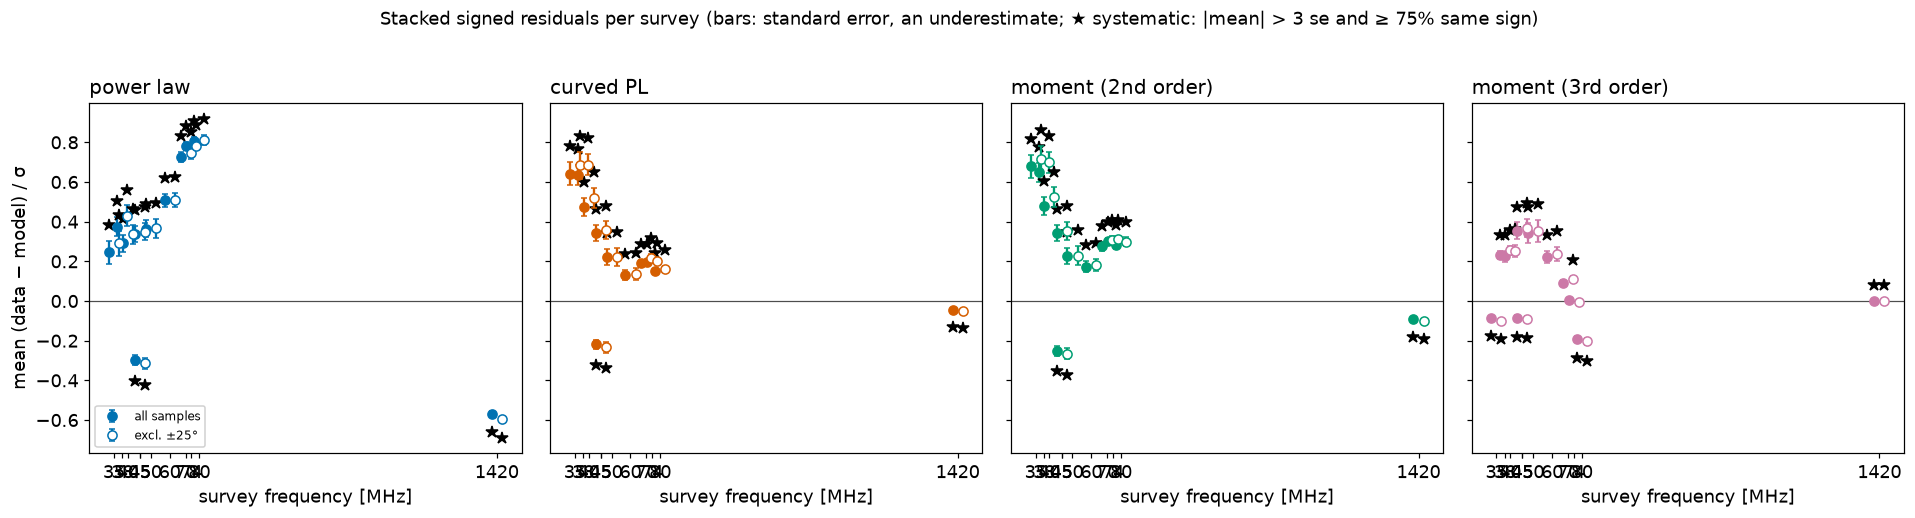

saved paper_outputs/model_comparison/diagnostic_plots/fig16_stacked_residuals.png
saved diagnostic_plots/part6_stacked_residuals.csv

             model        survey  frequency [MHz]     samples   n  mean residual [σ]  standard error [σ]  |mean| / se  fraction with the mean's sign  systematic
         power law        LWA 35             35.0 all samples 120              0.245               0.057        4.288                          0.758        True
         power law        LWA 35             35.0  excl. ±25° 103              0.290               0.064        4.514                          0.786        True
         power law  LWA1_38.fits             38.0 all samples 120              0.375               0.047        7.988                          0.833        True
         power law  LWA1_38.fits             38.0  excl. ±25° 103              0.430               0.051        8.402                          0.864        True
         power law  LWA1_40.fits             40.0 all samples

In [28]:
if not P5:
    print("Figure 16 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    KEYS16 = sorted({k for u in ALL_UNITS for k in PTS5[u][3]},
                    key=lambda k: float(PTS5[ALL_UNITS[0]][0][PTS5[ALL_UNITS[0]][3].index(k)]) if k in PTS5[ALL_UNITS[0]][3] else 0.0)
    NU16 = {k: float(next(PTS5[u][0][PTS5[u][3].index(k)] for u in ALL_UNITS if k in PTS5[u][3])) for k in KEYS16}
    R16 = {}
    for m in MODELS:
        for k in KEYS16:
            v = np.full(len(ALL_UNITS), np.nan)
            for i, u in enumerate(ALL_UNITS):
                nu, t, s, keys = PTS5[u]
                if k in keys:
                    j = keys.index(k)
                    v[i] = (t[j] - model_at(m, u, nu[j])[0]) / s[j]
            R16[(m, k)] = v
    rows = []
    for m in MODELS:
        for k in KEYS16:
            for lab, h in (("all samples", None), (f"excl. ±{MASK_HALF_WIDTH:g}°", MASK_HALF_WIDTH)):
                v = R16[(m, k)][keep(RA5, h)]; v = v[np.isfinite(v)]
                mean = float(np.mean(v)); se = float(np.std(v, ddof=1) / np.sqrt(len(v)))
                frac = float(np.mean(np.sign(v) == np.sign(mean))) if mean != 0 else 0.0
                rows.append({"model": SHORT[m], "survey": POINT_NAMES.get(k, k), "frequency [MHz]": NU16[k], "samples": lab,
                             "n": len(v), "mean residual [σ]": mean, "standard error [σ]": se, "|mean| / se": abs(mean) / se if se > 0 else np.inf,
                             "fraction with the mean's sign": frac,
                             "systematic": bool(se > 0 and abs(mean) > SYS_NSE * se and frac >= SYS_FRAC)})
    t16 = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, len(MODELS), figsize=(4.4 * len(MODELS), 4.6), sharey=True)
    for ax, m in zip(axes, MODELS):
        ax.axhline(0, color="0.3", lw=0.8)
        for lab, off, filled in (("all samples", 1 / 1.05, True), (f"excl. ±{MASK_HALF_WIDTH:g}°", 1.05, False)):
            sub = t16[(t16["model"] == SHORT[m]) & (t16["samples"] == lab)]
            x = sub["frequency [MHz]"].to_numpy() * off
            ax.errorbar(x, sub["mean residual [σ]"], yerr=sub["standard error [σ]"], fmt="o", ms=6, color=COL[m],
                        mfc=COL[m] if filled else "white", capsize=2, label=lab)
            for xi, yi, se, sy in zip(x, sub["mean residual [σ]"], sub["standard error [σ]"], sub["systematic"]):
                if sy:
                    ax.plot(xi, yi + np.sign(yi or 1) * (se + 0.08), "*", color="black", ms=8)
        ax.set_xscale("log"); ax.set_xlabel("survey frequency [MHz]"); ax.set_title(SHORT[m], loc="left")
        ax.set_xticks([NU16[k] for k in KEYS16]); ax.set_xticklabels([f"{NU16[k]:g}" for k in KEYS16])
        ax.minorticks_off()
    axes[0].set_ylabel("mean (data − model) / σ")
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, framealpha=0.9)
    fig.suptitle(f"Stacked signed residuals per survey (bars: standard error, an underestimate; ★ systematic: "
                 f"|mean| > {SYS_NSE:g} se and ≥ {SYS_FRAC:.0%} same sign)", y=1.02, fontsize=12)
    fig.tight_layout()
    save(fig, "fig16_stacked_residuals")
    t16.to_csv(PLOT_DIR / "part6_stacked_residuals.csv", index=False)
    print("saved diagnostic_plots/part6_stacked_residuals.csv\n")
    with pd.option_context("display.width", 220):
        print(t16.round(3).to_string(index=False))

#### Figure 17 — error-bar sensitivity (maximum likelihood only)

The errors of **all** fit points multiplied by 0.7 and by 1.5 (`ERR_SCALES`), and every model refitted at every sample with
the Part 5 fitter (same `ML_STARTS`, seeded; cached in `diagnostic_plots/cache/` under a key holding the scale and the data
key); scale 1.0 is Part 5. No sampler is run. For each extra-parameter model against the power law, the bars count the
samples where Δχ² (top) or ΔAIC (bottom) favours the model (< −2, purple), is indistinguishable (|Δ| ≤ 2, grey) or favours the
power law (> 2, orange), for each scale, with all samples and with the ±25° mask (n above each bar). Scaling every error by the
same factor c leaves the best fit unchanged and divides every χ² by c², so the refit is also a check of the fitter (printed).
Saved to `diagnostic_plots/part6_error_scale_counts.csv`.

errors × 0.7: fits loaded from paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_errscale_0.7.npz
  check: max |χ²(×0.7) · 0.7² − χ²(×1)| = 1.67e-06  (0 expected: a uniform scale leaves the best fit unchanged)
errors × 1.5: fits loaded from paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_errscale_1.5.npz
  check: max |χ²(×1.5) · 1.5² − χ²(×1)| = 1.16e-06  (0 expected: a uniform scale leaves the best fit unchanged)


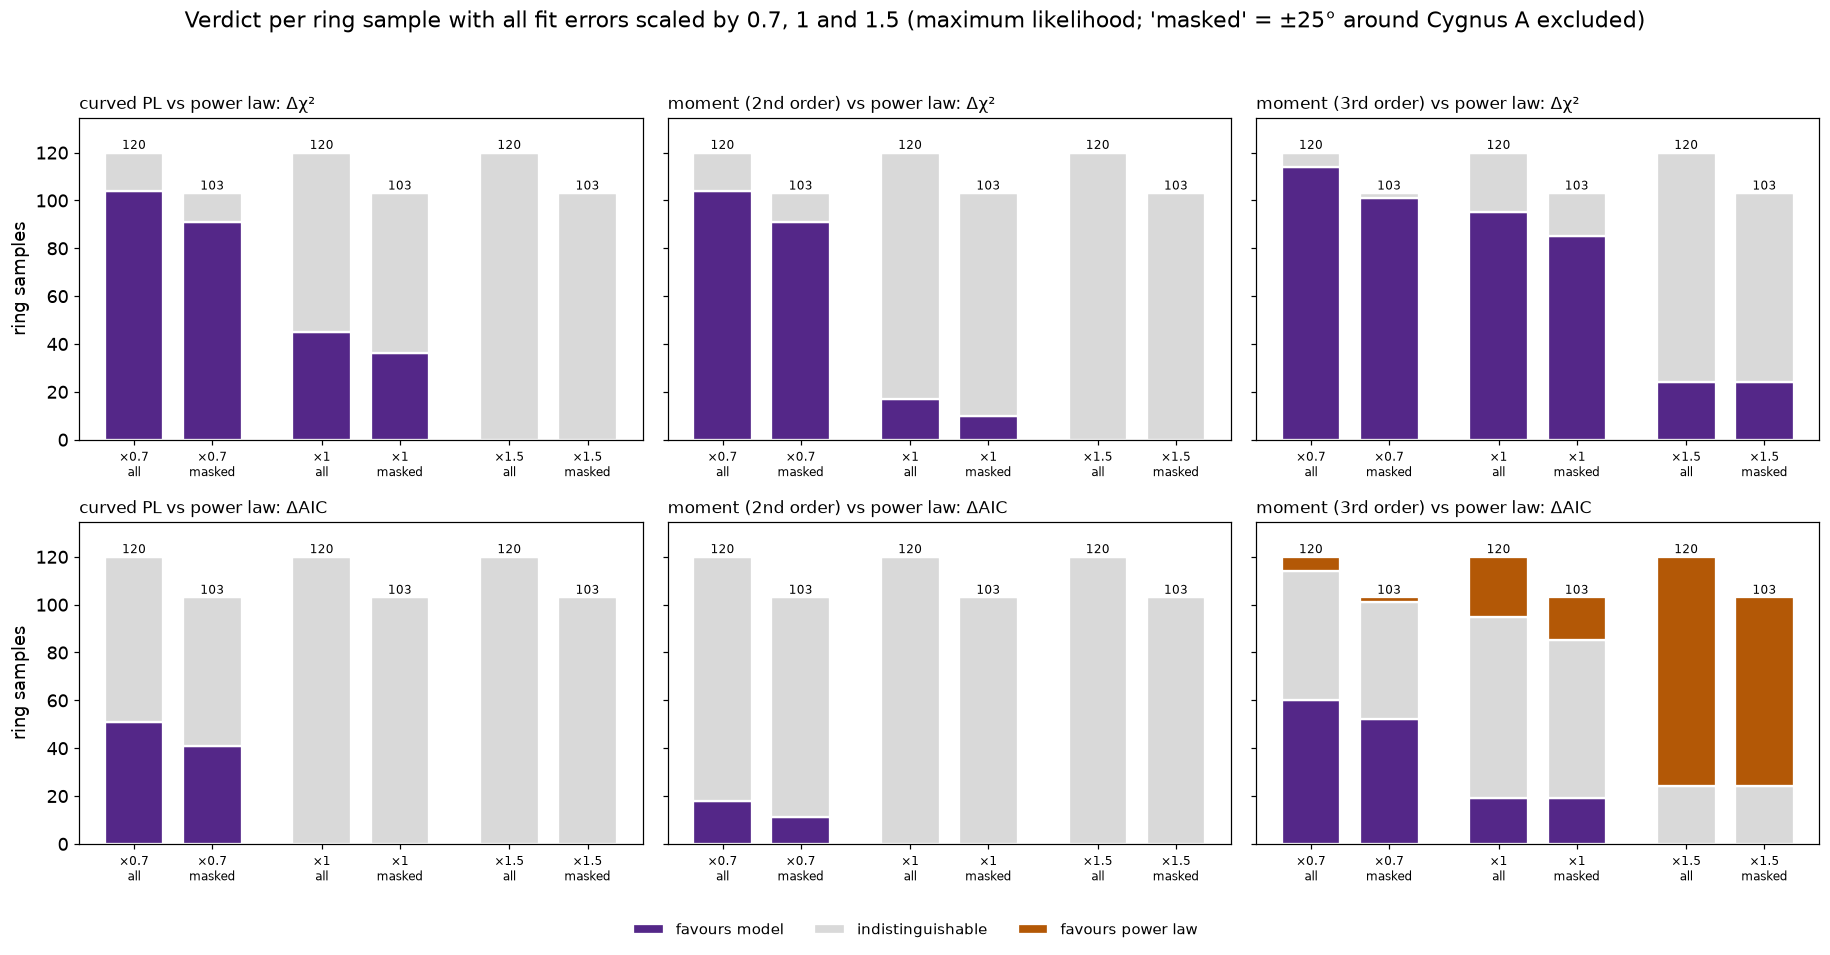

saved paper_outputs/model_comparison/diagnostic_plots/fig17_error_scale_sensitivity.png
saved diagnostic_plots/part6_error_scale_counts.csv

 error scale                      comparison statistic     samples   n  favours model  indistinguishable  favours power law  median Δ
         0.7          curved PL vs power law       Δχ² all samples 120            104                 16                  0     -3.73
         0.7          curved PL vs power law      ΔAIC all samples 120             51                 69                  0     -1.73
         0.7          curved PL vs power law       Δχ²  excl. ±25° 103             91                 12                  0     -3.71
         0.7          curved PL vs power law      ΔAIC  excl. ±25° 103             41                 62                  0     -1.71
         0.7 moment (2nd order) vs power law       Δχ² all samples 120            104                 16                  0     -2.94
         0.7 moment (2nd order) vs power law      ΔAIC 

In [29]:
if not RUN_ERR_SENS:
    print("Figure 17 skipped: RUN_ERR_SENS = False.")
elif not P5:
    print("Figure 17 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    C2S = {1.0: {m: np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS]) for m in MODELS}}
    for sc in ERR_SCALES:
        key = json.dumps({"ml": ML_KEY, "err_scale": float(sc)}, sort_keys=True)
        path = CACHE_DIR / f"ml_fits_errscale_{sc:g}.npz"
        z = np.load(path, allow_pickle=False) if path.exists() else None
        if z is not None and str(z["key"]) == key:
            C2S[sc] = {m: z[f"chi2__{slug(m)}"] for m in MODELS}
            print(f"errors × {sc:g}: fits loaded from {path.relative_to(REPO)}")
        else:
            rng = np.random.default_rng(0)
            out, c2s = {"key": key}, {m: np.zeros(len(ALL_UNITS)) for m in MODELS}
            for i, u in enumerate(ALL_UNITS):
                nu, t, s, keys = PTS5[u]
                for m in MODELS:
                    p = ml_fit(m, nu, t, s * sc, rng)
                    c2s[m][i] = float(np.sum(((t - MODELS[m][1](nu, p[None, :])[0]) / (s * sc)) ** 2))
                    out[f"u{u}__{slug(m)}"] = p
            out.update({f"chi2__{slug(m)}": c2s[m] for m in MODELS})
            CACHE_DIR.mkdir(parents=True, exist_ok=True)
            np.savez(path, **out)
            C2S[sc] = c2s
            print(f"errors × {sc:g}: refitted {len(MODELS)} models at {len(ALL_UNITS)} samples; saved {path.relative_to(REPO)}")
        dev = max(float(np.max(np.abs(C2S[sc][m] * sc ** 2 - C2S[1.0][m]))) for m in MODELS)
        print(f"  check: max |χ²(×{sc:g}) · {sc:g}² − χ²(×1)| = {dev:.2e}  (0 expected: a uniform scale leaves the best fit unchanged)")

    SCALES = sorted(C2S)
    rows = []
    for sc in SCALES:
        for m in EXTRA:
            dc2 = C2S[sc][m] - C2S[sc][PL]
            daic = dc2 + 2 * (len(MODELS[m][0]) - len(MODELS[PL][0]))
            for lab, h in (("all samples", None), (f"excl. ±{MASK_HALF_WIDTH:g}°", MASK_HALF_WIDTH)):
                k_ = keep(RA5, h)
                for stat, d in (("Δχ²", dc2), ("ΔAIC", daic)):
                    rows.append({"error scale": sc, "comparison": f"{SHORT[m]} vs power law", "statistic": stat,
                                 "samples": lab, "n": int(k_.sum()), **classify_ic(d[k_]), "median Δ": float(np.median(d[k_]))})
    t17 = pd.DataFrame(rows)
    fig, axes = plt.subplots(2, len(EXTRA), figsize=(5.6 * len(EXTRA), 8.6), sharey=True)
    CLS17 = [("favours model", CLASS_COLS[0]), ("indistinguishable", CLASS_COLS[2]), ("favours power law", CLASS_COLS[4])]
    for r, stat in enumerate(("Δχ²", "ΔAIC")):
        for c, m in enumerate(EXTRA):
            ax = axes[r, c]
            sub = t17[(t17["statistic"] == stat) & (t17["comparison"] == f"{SHORT[m]} vs power law")]
            labs, x = [], 0
            for sc in SCALES:
                for lab in ("all samples", f"excl. ±{MASK_HALF_WIDTH:g}°"):
                    row = sub[(sub["error scale"] == sc) & (sub["samples"] == lab)].iloc[0]
                    bottom = 0
                    for cl, col in CLS17:
                        ax.bar(x, row[cl], bottom=bottom, color=col, edgecolor="white", linewidth=1.5, width=0.75,
                               label=cl if (r == 0 and c == 0 and sc == SCALES[0] and lab == "all samples") else None)
                        bottom += row[cl]
                    ax.text(x, bottom + 1.5, f"{row['n']}", ha="center", fontsize=8)
                    labs.append(f"×{sc:g}\n{'all' if lab == 'all samples' else 'masked'}")
                    x += 1
                x += 0.4
            ax.set_xticks([i + 0.4 * (i // 2) for i in range(len(labs))]); ax.set_xticklabels(labs, fontsize=8)
            ax.set_title(f"{SHORT[m]} vs power law: {stat}", loc="left", fontsize=11)
            ax.set_ylim(0, 1.12 * len(ALL_UNITS))
            if c == 0:
                ax.set_ylabel("ring samples")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle("Verdict per ring sample with all fit errors scaled by 0.7, 1 and 1.5 (maximum likelihood; "
                 f"'masked' = ±{MASK_HALF_WIDTH:g}° around Cygnus A excluded)", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    save(fig, "fig17_error_scale_sensitivity")
    t17.to_csv(PLOT_DIR / "part6_error_scale_counts.csv", index=False)
    print("saved diagnostic_plots/part6_error_scale_counts.csv\n")
    with pd.option_context("display.width", 220):
        print(t17.round(2).to_string(index=False))

#### Part 6 in plain numbers

*From the evidence run of 2026-10-29 12:01 and the max-likelihood run of 2026-10-28 19:03, both on the same 4 points per
sample (LWA1 35, Maipu 45, LWA1 80, Stockert 1420; TRIS not fitted). Mask: ±25° around Cygnus A (±15° in brackets where
it differs). Counts are not independent votes.*

* **(a) The mask changes the counts, not the verdict.** Evidence, curved PL vs power law: favours the model / tie / favours
  the power law = 0 / 114 / 6 with all 120 samples, 0 / 106 / 4 without ±15° and 0 / 99 / 4 without ±25°; 68 of the 120
  are borderline (within 0.4 of ±1). Moment order 2: 0 / 58 / 62 → 0 / 57 / 53 → 0 / 56 / 47. Order 3: 0 / 41 / 79 →
  0 / 41 / 69 → 0 / 39 / 64. With ln L_max (no Occam penalty) the curved PL and moment order 2 tie with the power law at
  every sample with or without the mask; order 3 is "favoured" at the same 23 samples in every case, all outside the mask.
* **(b) The evidence difference is almost all Occam penalty.** The best-fit gain over the power law is small (median
  ΔlnL_max +0.30 curved PL, +0.25 moment order 2, +0.53 order 3), and the Occam penalty is larger at every sample: median
  0.94 (range 0.38–1.44), 1.26 (0.31–1.99) and 1.76 (0.87–3.02). So ΔlnZ is negative at all 120 samples for all three
  models (median −0.64, −1.01, −1.10). The mask moves these medians by less than 0.1.
* **(c) AIC and BIC lean the same way as the evidence but call more ties.** Curved PL and moment order 2 are
  indistinguishable from the power law at every sample by both criteria (median ΔAIC +1.40 and +1.51, ΔBIC +0.78 and
  +0.89, on the power-law side); the evidence instead favours the power law over moment order 2 at 62 samples. Order 3:
  AIC favours the power law at 97 samples (80 with the mask) and ties at 23; BIC favours the power law at 13 (6). Neither
  criterion favours an extra-parameter model anywhere. AICc is undefined at N = 4.
* **(d) At 600 MHz the curved power law predicts TRIS best, by a wide margin.** Median standardised miss z: curved PL
  −0.21 (+0.29 with the mask), median |z| 5.2 (3.9), within 1σ at 21 samples; power law −21.3 (−15.4), within 1σ at
  1 sample; moment order 2 −8.4 (−8.1); order 3 +109. At 820 MHz (larger TRIS error) the three lower-order models are
  close: median |z| 0.58 for moment order 2 (0.44 with the mask; within 1σ at 94 samples), 0.75 for the power law (80)
  and 0.76 for the curved PL (83); order 3 is at 6.3.
* **(e) Under the power law all four surveys carry systematic residuals; the extra parameter moves them, not removes
  them.** Power law: LWA1 80 +0.91σ (all 120 samples positive), Stockert −0.25σ (all negative), Maipu −0.07σ (85%
  negative), LWA1 35 +0.22σ (+0.26σ and 77% positive with the mask, where it passes the test). Curved PL / moment order 2:
  LWA1 80 drops to +0.29σ / +0.43σ and Stockert to −0.03σ / −0.05σ, but LWA1 35 rises to +0.60σ; all four are still
  flagged (85–87% same sign). Order 3 passes through every point, so its residuals are below 0.015σ and its flags are
  numerical noise.
* **(f) Scaling all errors by 0.7 or 1.5 does not change the verdict for the curved PL or moment order 2.** Both stay
  indistinguishable from the power law at every sample by Δχ² and ΔAIC at ×0.7, ×1 and ×1.5 (curved PL median Δχ² −1.23,
  −0.60, −0.27). Only order 3 moves: Δχ² favours it at 73 / 23 / 0 samples and ΔAIC favours the power law at 47 / 97 / 120.
  The refits reproduce χ²/c² to 1.5 × 10⁻⁶, as a uniform scale should.
* **Skipped:** no figure was skipped (all of Figures 12–17 ran; Figure 17's refits are cached in
  `diagnostic_plots/cache/ml_fits_errscale_*.npz`).

## Summary

*From the run of 2026-10-29 (`evidence_per_unit_tod.csv` written 12:01; `comparison.statistic: evidence`, so the Occam
penalty is included). The max-likelihood run on the same points (`maxlike_per_unit_tod.csv`, 2026-10-28 19:03) is
quoted for comparison.*

**What was looked at.** Every one of the 120 ring samples has the same **4 points**: LWA1 35, Maipu 45, LWA1 80 and
Stockert 1420 (the 2026-10-29 run's `data.datasets`; **TRIS 600 and 820 are not in the fit**). Beam-matched TODs, published survey error
bars. Each ln Z carries a sampling error of about ±0.2 (median 0.18–0.20 by model), so a difference between two models
is uncertain by about ±0.27. Parts 2–4 rerun the evidence on 6 samples (Part 4: 3 samples) on the same data; Part 5
fits every model at every sample at maximum likelihood and compares the fits with the TRIS rings, which they did not
see.

**Findings, in plain language.**

* **The power law has the highest evidence at every one of the 120 samples,** but mostly not by much.
* **Curved power law vs power law: a tie almost everywhere.** In 114 of 120 samples |ΔlnZ| ≤ 1 (median −0.64); the
  power law is favoured in the other 6 (RA 33°, 39°, 252°, 273°, 288°, 297°; lowest −1.22). The curved model is never
  favoured, Cygnus included.
* **The moment expansions lose more often.** Order 2: tie in 58 samples, power law favoured in 62 (median −1.01,
  lowest −1.76). Order 3: tie in 41, power law favoured in 79 (median −1.10, lowest −1.97). Neither is ever favoured,
  and no difference anywhere exceeds 2 in size (no strong preference).
* **Among the extra-parameter models nothing separates.** Moment order 2 vs curved PL: tie in 119; order 3 vs order 2:
  tie in all 120; order 3 vs curved PL: tie in 116, curved favoured in 4.
* **The data barely use the extra parameter (Part 2).** It raises the best-fit ln L by only 0.1–0.7 at the six rerun
  samples (Cygnus included), less than its Occam cost, so the evidence falls by 0.3–1.2.
* **The curved model's deficit is all Occam penalty (Part 3).** Narrowing the C prior from ±0.5 to ±0.2 or ±0.1 moves
  curved − power law from −0.3…−0.8 to −0.06…+0.25, i.e. to zero: the 4 points are consistent with C = 0 but do not
  rule out moderate curvature. The sign flips at 4 of the 5 samples, all inside the tie band.
* **The evidences are converged, but the verdicts are borderline (Part 4).** UltraNest is within 0.33 of the exact
  integral, but most exact ΔlnZ values lie within 0.3 of −1, so individual "power law favoured" verdicts can flip
  between runs. None turns positive.
* **Without the Occam penalty it is a tie (max-likelihood run, same points).** The best-fit ln L gain over the power law
  is a median +0.30 (curved PL), +0.25 (moment order 2) and +0.53 (order 3), inside ±1 at every sample, except order 3
  at 23 samples. Order 3 has 4 parameters for 4 points, so it passes through every point (χ² = 0) and its "gain" means
  nothing.
* **χ² (Part 5).** Median χ² (mean in brackets): power law 1.07 (1.44) for ν = 2, curved PL 0.43 (0.89) and moment
  order 2 0.52 (0.99) for ν = 1, order 3 0 (ν = 0). The power law fits the 4 points well (median χ²/ν 0.53; > 2 at only
  3 samples). Its χ² comes mostly from LWA 80 (median share 85%); the curved models' from LWA 35 (62–77%).
* **TRIS, held out, separates the models (Part 5, Fig 10).** Extrapolated to 600.5 MHz, where TRIS's error is 0.07 K,
  the curved power law lands on the ring (median −0.01 K, rms 0.51 K). The power law is low almost everywhere (median
  −1.44 K, rms 2.0 K, up to 5.8 K low at Cygnus; more than 1σ off at 119 of 120 samples). Moment order 2 is in between
  (−0.56 K) and order 3 is far off (+7.3 K). At 817.8 MHz, where TRIS's error is 0.43 K, the power law, curved PL and
  moment order 2 are all within about 0.2 K median; order 3 is +2.7 K off.
* **No sums.** Neighbouring ring samples share most of the beam, so the counts above are not 120 independent votes; a
  summed ln Z or χ² would overstate the evidence many times over.

**What this means.** With only the four survey maps (35–1420 MHz) the comparison cannot tell the models apart: the
power law fits them well, the extra parameter buys almost nothing, and the evidence therefore prefers the power law,
weakly (ties at most samples, never strong). The curvature found before (at Cygnus) came from the TRIS points. The
held-out TRIS data point the other way: at 600 MHz the power law fitted to the surveys misses TRIS by about 1.4 K
(about 20σ), while the curved power law predicts it to within about 0.01 K median. So the survey points alone favour
the simplest model, but the curvature is needed to join the surveys to TRIS. Order 3 has no degrees of freedom with
4 points and should not be read.

In [30]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")

total notebook run time: 221 s (0h 03m 41s)
